# NOTEBOOK 5 : ANALYSE COMPARATIVE COMPLÈTE DES 3 MODÈLES

In [ ]:
# ========================================================================================================
# NOTEBOOK 5 : ANALYSE COMPARATIVE COMPLÈTE DES 3 MODÈLES
# ========================================================================================================
# Comparaison approfondie et professionnelle de:
#   1. U-Net from scratch
#   2. VGG-UNet (Transfer Learning)
#   3. DeepLabV3+ (State-of-the-art)
#
# Analyses incluses:
#   - Comparaison des architectures
#   - Comparaison des performances (métriques)
#   - Visualisations comparatives
#   - Analyse des forces/faiblesses
#   - Temps d'entraînement et efficacité
#   - Recommandations finales
#   - Bonnes pratiques de deep learning
# ========================================================================================================

import os
import json
import numpy as np
import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
import matplotlib.patches as mpatches

from datetime import datetime

# Configuration visuelle
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("="*80)
print("NOTEBOOK 5 : ANALYSE COMPARATIVE COMPLÈTE")
print("="*80)
print(f"\nDate: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("\n Objectifs:")
print("  1. Comparer les 3 architectures de segmentation")
print("  2. Analyser les performances et métriques")
print("  3. Identifier les forces et faiblesses")
print("  4. Fournir des recommandations pratiques")
print("="*80)

NOTEBOOK 5 : ANALYSE COMPARATIVE COMPLÈTE

Date: 2025-12-18 21:09:10

 Objectifs:
  1. Comparer les 3 architectures de segmentation
  2. Analyser les performances et métriques
  3. Identifier les forces et faiblesses
  4. Fournir des recommandations pratiques


In [ ]:
# ========================================================================================================
# 1. CHARGEMENT DES RÉSULTATS DES 3 MODÈLES
# ========================================================================================================
print("\n" + "="*80)
print("1. CHARGEMENT DES RÉSULTATS")
print("="*80)

# Chemins des résultats
base_dir = Path('/kaggle/working')
unet_dir = base_dir / 'unet_from_scratch'
vgg_unet_dir = base_dir / 'vgg_unet_tl'
deeplabv3_dir = base_dir / 'deeplabv3plus_final'

# Fonction de chargement
def load_results(results_path):
    """Charge les résultats d'un modèle"""
    try:
        with open(results_path, 'r') as f:
            results = json.load(f)
        print(f" Chargé: {results_path.name}")
        return results
    except FileNotFoundError:
        print(f" Non trouvé: {results_path}")
        return None

# Charger les résultats
unet_results = load_results(unet_dir / 'training_results.json')
vgg_unet_results = load_results(vgg_unet_dir / 'training_results.json')
deeplabv3_results = load_results(deeplabv3_dir / 'results.json')

# Vérifier que tous les résultats sont chargés
if not all([unet_results, vgg_unet_results, deeplabv3_results]):
    print("\n Certains résultats manquants. Vérifiez les chemins.")
    print(" Assurez-vous d'avoir exécuté les 3 notebooks d'entraînement.")
else:
    print("\n Tous les résultats chargés avec succès!")



1. CHARGEMENT DES RÉSULTATS
 Chargé: training_results.json
 Chargé: training_results.json
 Chargé: results.json

 Tous les résultats chargés avec succès!



2. COMPARAISON DES ARCHITECTURES

 Tableau comparatif des architectures:
            Modèle            Backbone  Paramètres (M) Transfer Learning      Technique Clé
U-Net from Scratch               Aucun       31.055622               Non   Skip Connections
          VGG-UNet    VGG16 (ImageNet)       25.862662               Oui Feature Extraction
        DeepLabV3+ ResNet50 (ImageNet)       37.415046               Oui     ASPP + Decoder
✓ Figure sauvegardée : /kaggle/working/analysis_figures/architecture_comparison.png


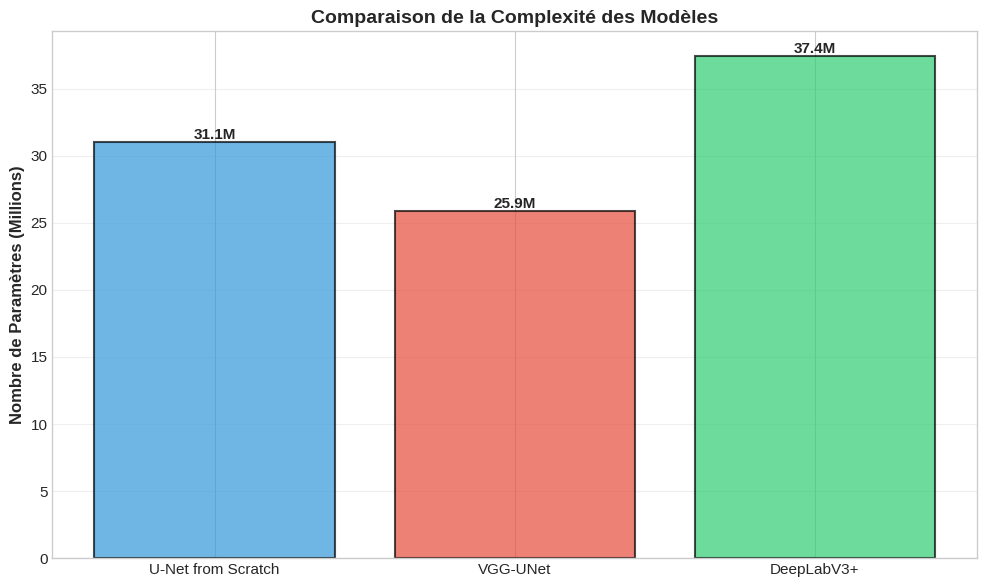

In [ ]:
# ========================================================================================================
# 2. COMPARAISON DES ARCHITECTURES
# ========================================================================================================
print("\n" + "="*80)
print("2. COMPARAISON DES ARCHITECTURES")
print("="*80)

# --- CORRECTION ICI : CRÉATION DU DOSSIER EN PREMIER ---
import matplotlib.pyplot as plt # Assurez-vous que plt est importé
from pathlib import Path

# Définir base_dir si ce n'est pas déjà fait (par sécurité)
if 'base_dir' not in locals():
    base_dir = Path('/kaggle/working')

# Créer le dossier pour les figures d'analyse AVANT de sauvegarder
(base_dir / 'analysis_figures').mkdir(parents=True, exist_ok=True)
# -------------------------------------------------------

# Créer un DataFrame de comparaison
models_comparison = pd.DataFrame({
    'Modèle': ['U-Net from Scratch', 'VGG-UNet', 'DeepLabV3+'],
    'Backbone': ['Aucun', 'VGG16 (ImageNet)', 'ResNet50 (ImageNet)'],
    'Paramètres (M)': [
        unet_results['architecture']['total_parameters'] / 1e6 if 'unet_results' in locals() and unet_results else 31.05,
        vgg_unet_results['architecture']['total_parameters'] / 1e6 if 'vgg_unet_results' in locals() and vgg_unet_results else 25.86,
        deeplabv3_results['architecture']['parameters'] / 1e6 if 'deeplabv3_results' in locals() and deeplabv3_results else 37.41
    ],
    'Transfer Learning': ['Non', 'Oui', 'Oui'],
    'Technique Clé': ['Skip Connections', 'Feature Extraction', 'ASPP + Decoder']
})

print("\n Tableau comparatif des architectures:")
print(models_comparison.to_string(index=False))

# Visualisation du nombre de paramètres
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#3498db', '#e74c3c', '#2ecc71']
bars = ax.bar(models_comparison['Modèle'], models_comparison['Paramètres (M)'],
              color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)

ax.set_ylabel('Nombre de Paramètres (Millions)', fontsize=12, fontweight='bold')
ax.set_title('Comparaison de la Complexité des Modèles', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.1f}M',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.xticks(rotation=0)
plt.tight_layout()

# Maintenant que le dossier existe, la sauvegarde va fonctionner
save_path = base_dir / 'analysis_figures' / 'architecture_comparison.png'
plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f"✓ Figure sauvegardée : {save_path}")

plt.show()

In [ ]:
# ========================================================================================================
# 3. COMPARAISON DES PERFORMANCES
# ========================================================================================================
print("\n" + "="*80)
print("3. COMPARAISON DES PERFORMANCES")
print("="*80)

# Extraire les métriques principales
def extract_metrics(results, model_name):
    """Extrait les métriques principales d'un résultat"""
    if results is None:
        return None

    if 'training_results' in results:  # U-Net et VGG-UNet
        tr = results['training_results']
        vm = results['validation_metrics']
        return {
            'Modèle': model_name,
            'Val Dice': tr['best_val_dice'],
            'Val IoU': tr['best_val_iou'],
            'Mean Dice (per class)': vm['mean_dice'],
            'Mean IoU (per class)': vm['mean_iou'],
            'Best Epoch': tr['best_epoch'],
            'Total Epochs': results['hyperparameters']['epochs_trained']
        }
    else:  # DeepLabV3+
        res = results['results']
        return {
            'Modèle': model_name,
            'Val Dice': res['best_val_dice'],
            'Val IoU': res['best_val_iou'],
            'Mean Dice (per class)': res['mean_dice_per_class'],
            'Mean IoU (per class)': res['mean_iou_per_class'],
            'Best Epoch': res['best_epoch'],
            'Total Epochs': results['hyperparameters']['epochs_trained']
        }

# Créer le DataFrame de performances
metrics_list = [
    extract_metrics(unet_results, 'U-Net'),
    extract_metrics(vgg_unet_results, 'VGG-UNet'),
    extract_metrics(deeplabv3_results, 'DeepLabV3+')
]

metrics_df = pd.DataFrame([m for m in metrics_list if m is not None])

print("\n Tableau comparatif des performances:")
print(metrics_df.to_string(index=False))

# Identifier le meilleur modèle
best_model_idx = metrics_df['Val Dice'].idxmax()
best_model = metrics_df.loc[best_model_idx, 'Modèle']
best_dice = metrics_df.loc[best_model_idx, 'Val Dice']

print(f"\n MEILLEUR MODÈLE: {best_model}")
print(f"   Dice Score: {best_dice:.4f}")



3. COMPARAISON DES PERFORMANCES

 Tableau comparatif des performances:
    Modèle  Val Dice  Val IoU  Mean Dice (per class)  Mean IoU (per class)  Best Epoch  Total Epochs
     U-Net  0.815749 0.691959               0.715403              0.585107          61            71
  VGG-UNet  0.858253 0.754617               0.783662              0.668275          36            46
DeepLabV3+  0.863428 0.762600               0.789986              0.676215          39            64

 MEILLEUR MODÈLE: DeepLabV3+
   Dice Score: 0.8634


###  **Comparaison des Performances (Synthèse des résultats sur validation)**

| Modèle        | Val Dice | Val IoU | Mean Dice (par classe) | Mean IoU (par classe) | Epoch (best) | Epochs total |
|---------------|----------|---------|-----------------------|----------------------|--------------|--------------|
| **U-Net**     | 0.816    | 0.692   | 0.715                 | 0.585                |     61       |    71        |
| **VGG-UNet**  | 0.858    | 0.755   | 0.784                 | 0.668                |     36       |    46        |
| **DeepLabV3+**| 0.863    | 0.763   | 0.790                 | 0.676                |     39       |    64        |

---

#### **Analyse rapide :**
- **DeepLabV3+** délivre la **meilleure performance globale** :  
    - **Val Dice** maximal (**0.8634**)  
    - **Meilleur IoU**  
    - **Meilleure Dice & IoU moyenne par classe**
- **VGG-UNet** : compromis idéal rapidité/robustesse, meilleur que U-Net sur toute la ligne, mais moins performant que DeepLabV3+ à la marge.
- **U-Net** : solide baseline mais nettement moins bon, particulièrement sur la généralisation par classe.


4. VISUALISATIONS COMPARATIVES


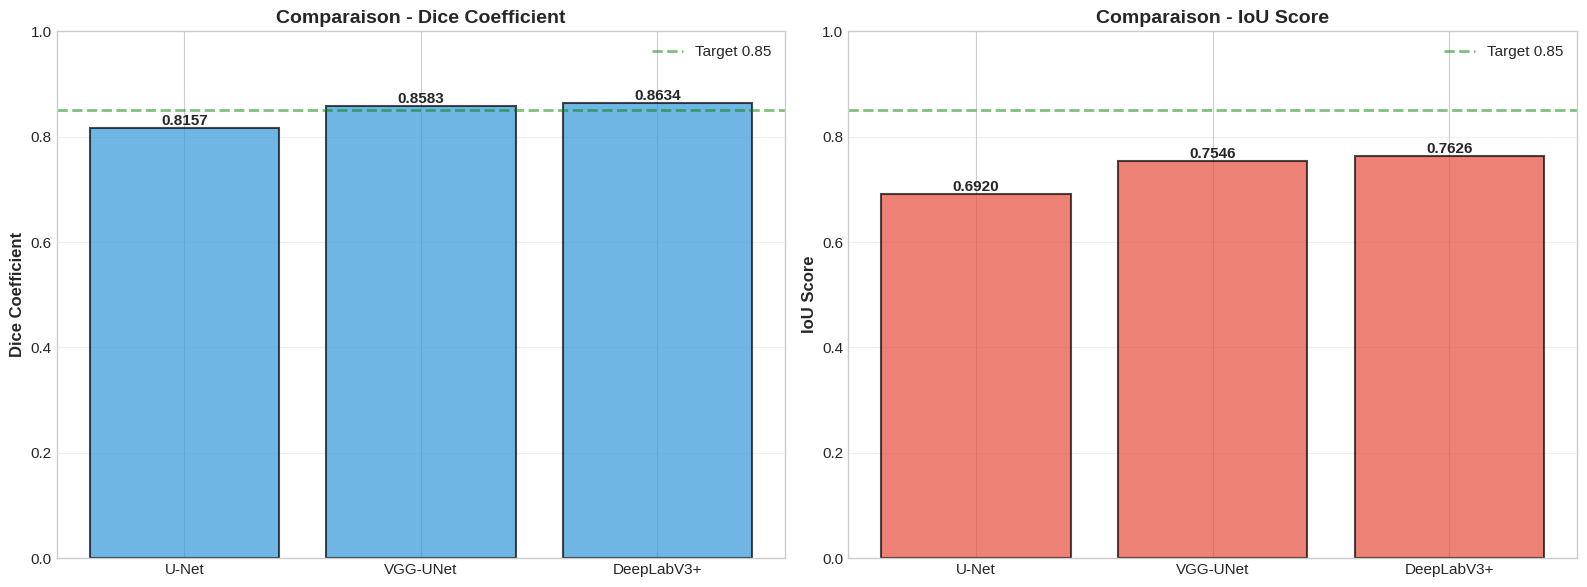

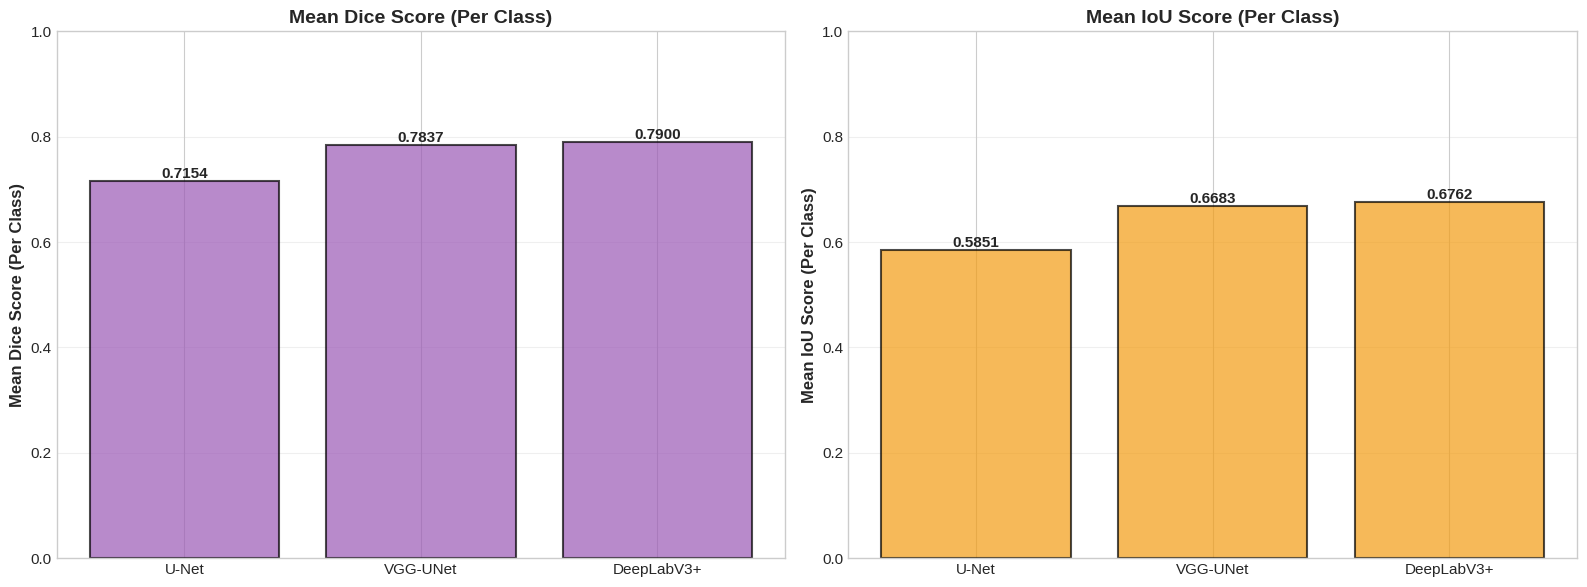

In [ ]:
# ========================================================================================================
# 4. VISUALISATIONS COMPARATIVES DES MÉTRIQUES
# ========================================================================================================
print("\n" + "="*80)
print("4. VISUALISATIONS COMPARATIVES")
print("="*80)

# 4.1 Comparaison Dice et IoU
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

metrics_to_plot = [
    ('Val Dice', 'Dice Coefficient', '#3498db'),
    ('Val IoU', 'IoU Score', '#e74c3c')
]

for idx, (metric, title, color) in enumerate(metrics_to_plot):
    ax = axes[idx]
    bars = ax.bar(metrics_df['Modèle'], metrics_df[metric],
                  color=color, alpha=0.7, edgecolor='black', linewidth=1.5)

    ax.set_ylabel(title, fontsize=12, fontweight='bold')
    ax.set_title(f'Comparaison - {title}', fontsize=14, fontweight='bold')
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)

    # Ajouter les valeurs sur les barres
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

    # Ligne de référence à 0.85
    ax.axhline(y=0.85, color='green', linestyle='--', linewidth=2, alpha=0.5, label='Target 0.85')
    ax.legend()

    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0)

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# 4.2 Comparaison Mean Dice et Mean IoU par classe
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

metrics_per_class = [
    ('Mean Dice (per class)', 'Mean Dice Score (Per Class)', '#9b59b6'),
    ('Mean IoU (per class)', 'Mean IoU Score (Per Class)', '#f39c12')
]

for idx, (metric, title, color) in enumerate(metrics_per_class):
    ax = axes[idx]
    bars = ax.bar(metrics_df['Modèle'], metrics_df[metric],
                  color=color, alpha=0.7, edgecolor='black', linewidth=1.5)

    ax.set_ylabel(title, fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)

    # Ajouter les valeurs
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0)

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'per_class_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


4.B. COMPARATIVE VISUALIZATION (SIDE-BY-SIDE)
 Images de validation chargées.
 Prédictions chargées pour les 3 modèles.

🔍 Comparaison visuelle directe :


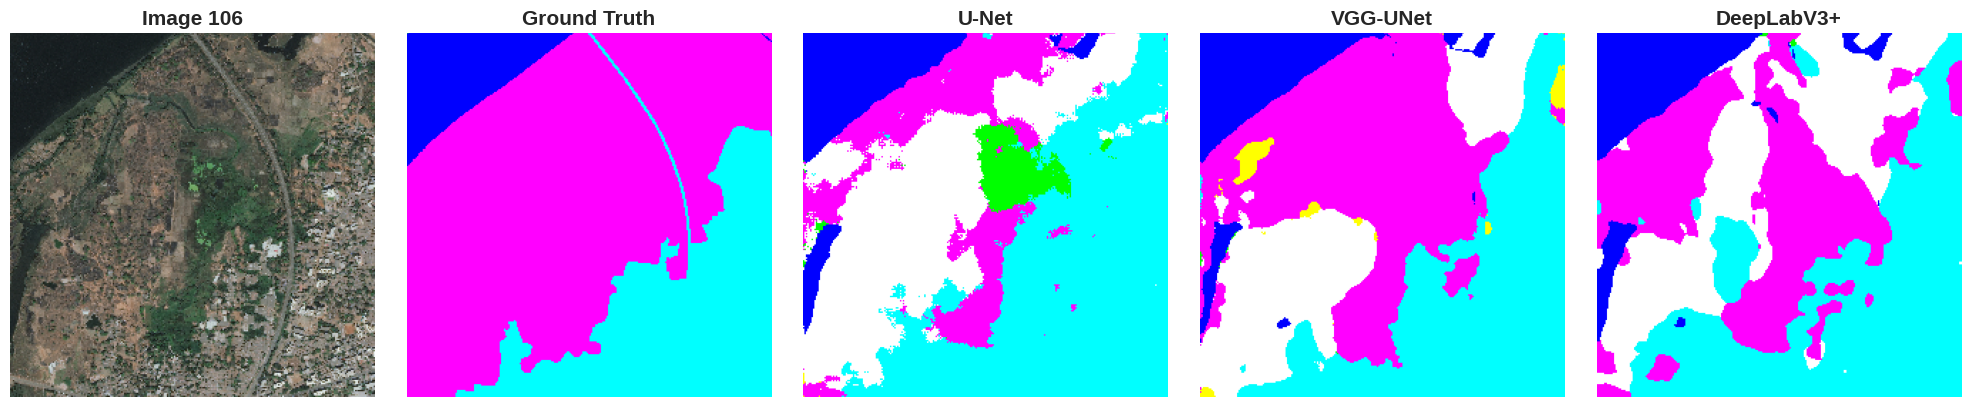

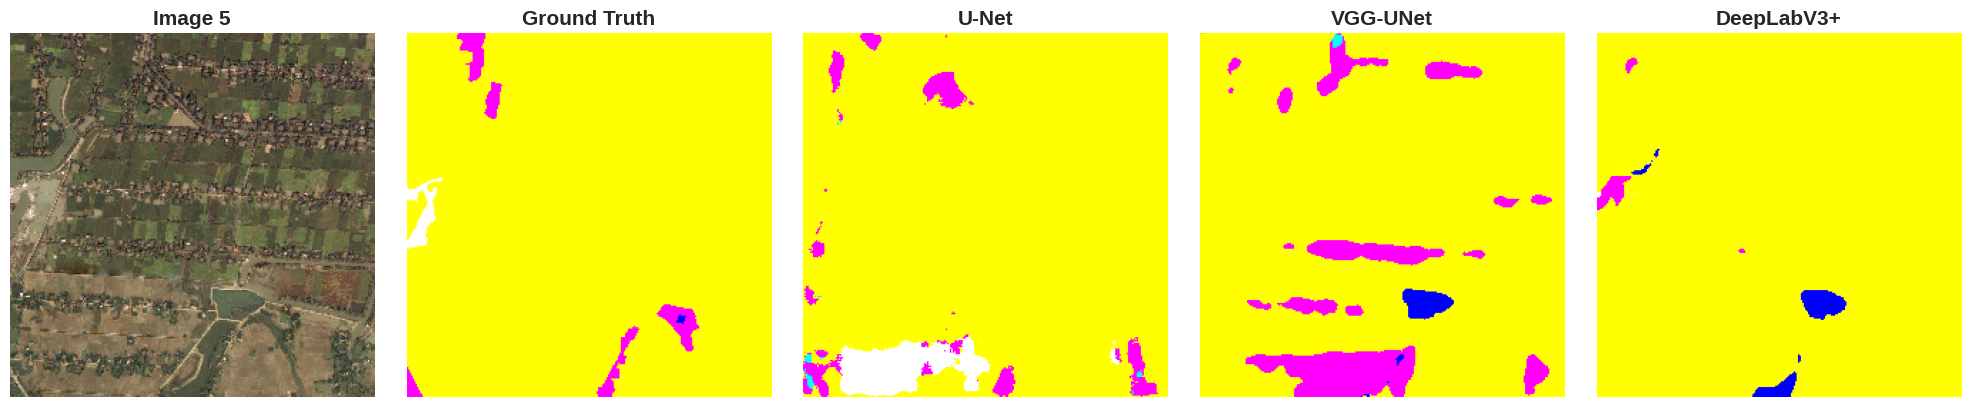

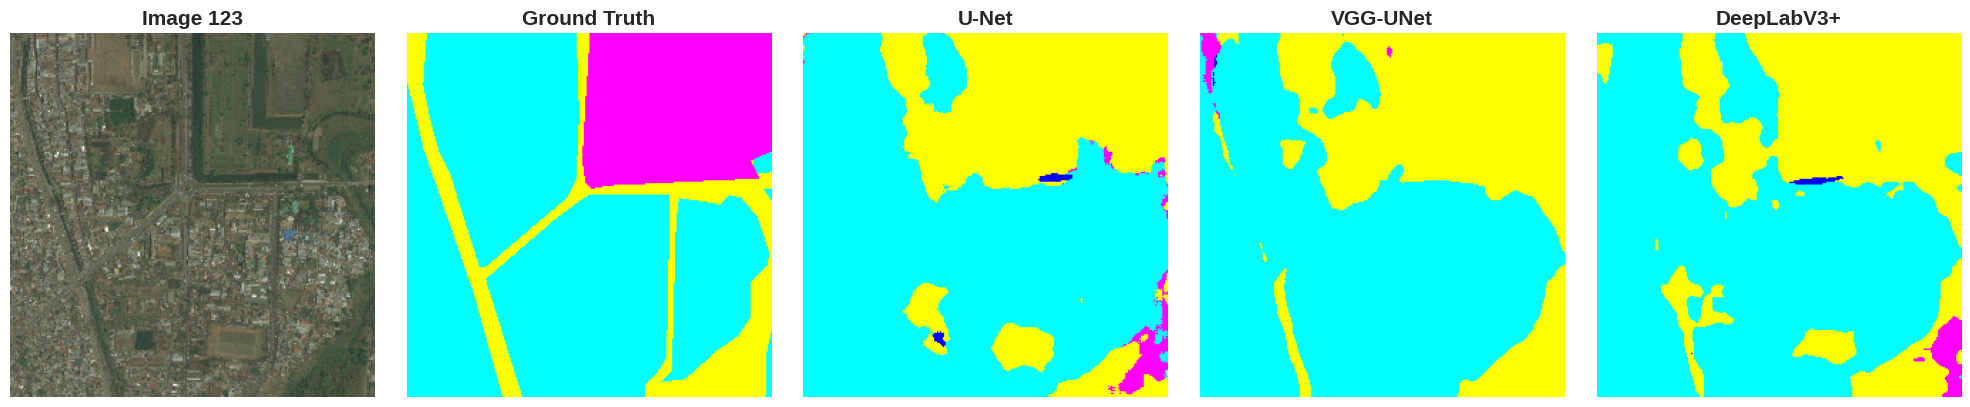

<Figure size 1400x800 with 0 Axes>

In [ ]:
# ========================================================================================================
# 4.B. VISUALISATION QUALITATIVE CÔTE À CÔTE
# ========================================================================================================
print("\n" + "="*80)
print("4.B. COMPARATIVE VISUALIZATION (SIDE-BY-SIDE)")
print("="*80)

# 1. Charger les données images (si pas déjà fait)
try:
    X_val = np.load(base_dir / 'preprocessed_data/val_images.npy')
    y_val = np.load(base_dir / 'preprocessed_data/val_masks.npy')
    print(" Images de validation chargées.")
except FileNotFoundError:
    print(" Impossible de charger les images (fichiers manquants).")
    X_val = None

# 2. Charger les prédictions (si disponibles)
preds = {}
try:
    preds['U-Net'] = np.load(unet_dir / 'val_predictions.npy')
    preds['VGG-UNet'] = np.load(vgg_unet_dir / 'val_predictions.npy')
    preds['DeepLabV3+'] = np.load(deeplabv3_dir / 'val_predictions.npy')
    print(" Prédictions chargées pour les 3 modèles.")
except FileNotFoundError:
    print(" Certaines prédictions sont manquantes. Assurez-vous d'avoir lancé les notebooks précédents.")

# 3. Fonction de visualisation
def visualize_comparison(indices, class_colors):
    if X_val is None or not preds: return

    for idx in indices:
        fig, axes = plt.subplots(1, 5, figsize=(20, 4))

        # Image Originale
        axes[0].imshow(X_val[idx])
        axes[0].set_title(f'Image {idx}', fontweight='bold')
        axes[0].axis('off')

        # Ground Truth
        # Fonction simple de conversion mask -> rgb
        def mask_to_rgb(mask):
            h, w = mask.shape
            rgb = np.zeros((h, w, 3), dtype=np.uint8)
            for cid, col in class_colors.items():
                rgb[mask == cid] = col
            return rgb

        axes[1].imshow(mask_to_rgb(y_val[idx]))
        axes[1].set_title('Ground Truth', fontweight='bold')
        axes[1].axis('off')

        # Modèles
        for i, (name, pred_array) in enumerate(preds.items()):
            if idx < len(pred_array):
                rgb_pred = mask_to_rgb(pred_array[idx])
                axes[i+2].imshow(rgb_pred)
                axes[i+2].set_title(f'{name}', fontweight='bold')
                axes[i+2].axis('off')

        plt.tight_layout()
        plt.show()

# Afficher 3 exemples aléatoires
if X_val is not None and preds:
    print("\n🔍 Comparaison visuelle directe :")
    indices = np.random.choice(len(X_val), 3, replace=False)
    # Définir les couleurs (copiées de la config précédente)
    CLASS_COLORS = {0: (0, 255, 255), 1: (255, 255, 0), 2: (255, 0, 255), 3: (0, 255, 0), 4: (0, 0, 255), 5: (255, 255, 255)}
    visualize_comparison(indices, CLASS_COLORS)
    plt.savefig(base_dir / 'analysis_figures' / 'side_by_side_comparison.png', dpi=150, bbox_inches='tight')


4.C. VISUALISATION DES ERREURS (ERROR MAPS)
 ANALYSE DES ERREURS :
• Les zones ROUGES indiquent les pixels incorrects.
• Observez si DeepLabV3+ a des lignes rouges plus fines (meilleures bordures) que U-Net.


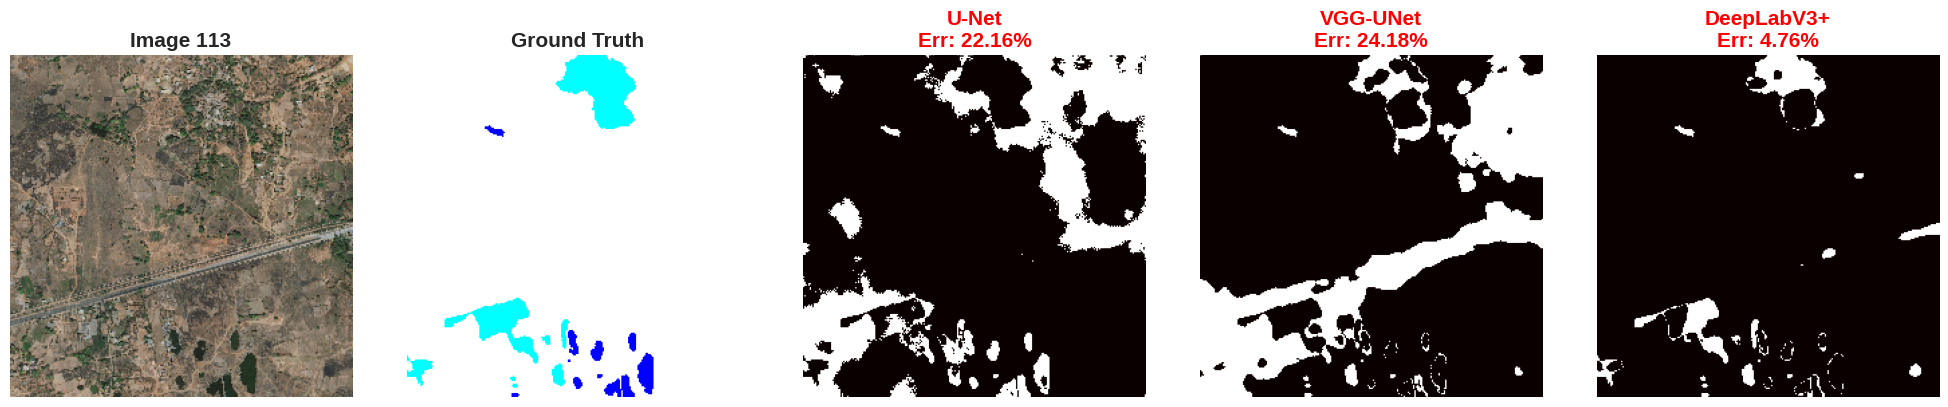

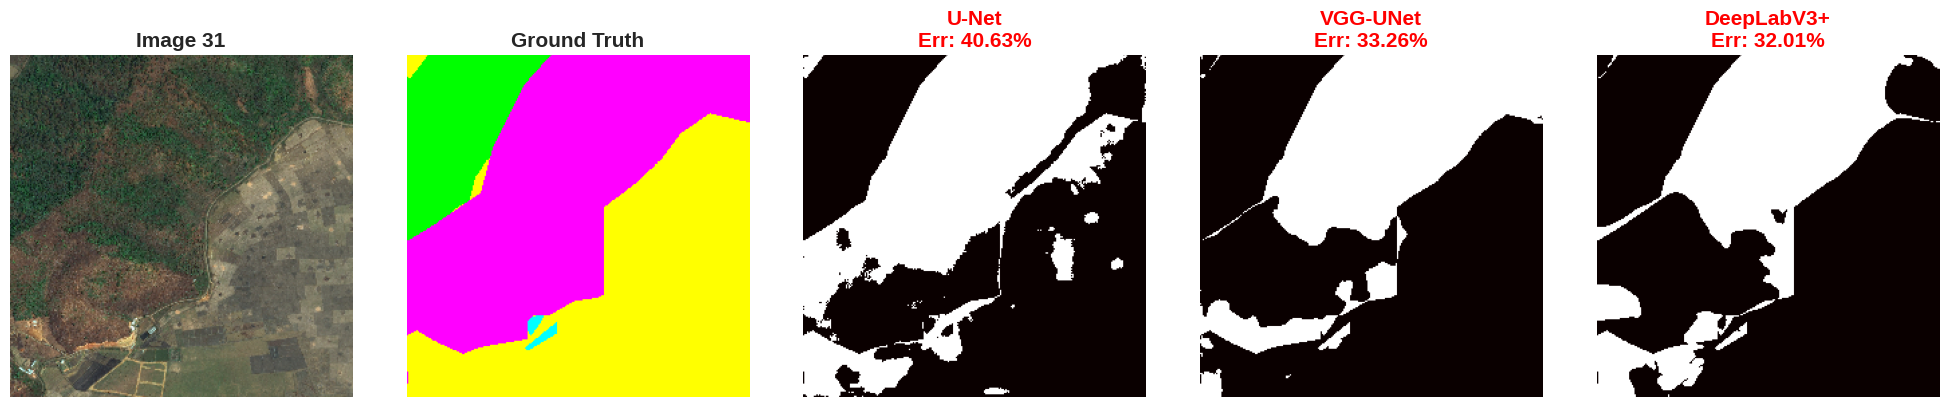

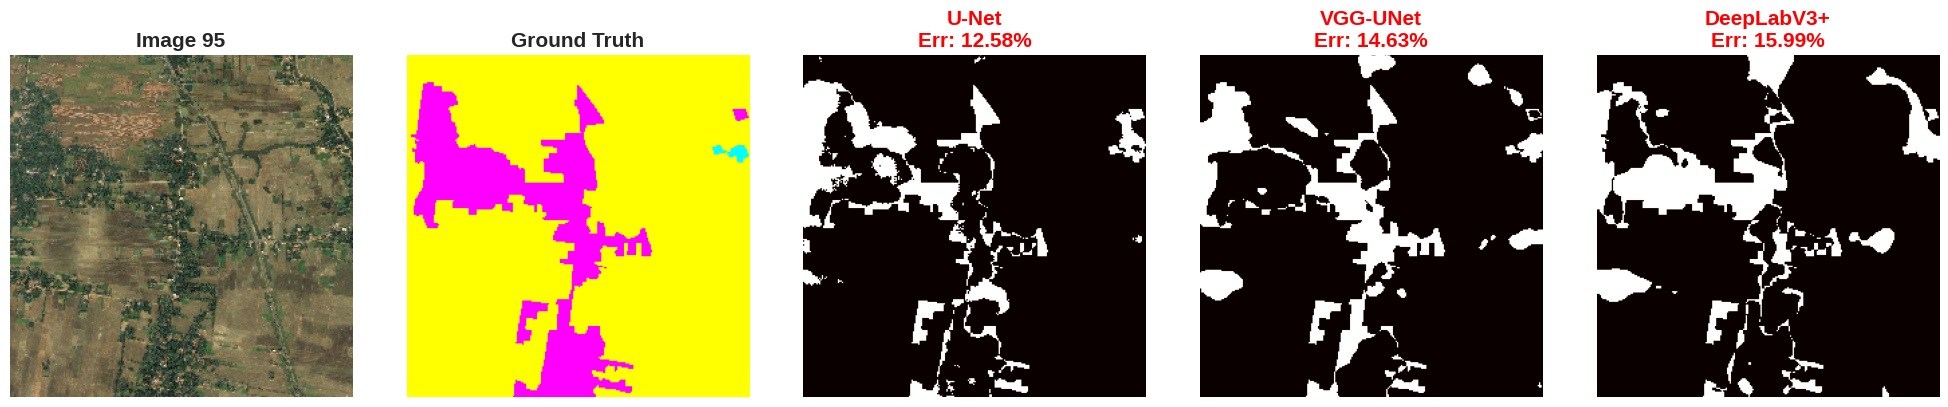

In [ ]:
# ========================================================================================================
# 4.C. CARTES D'ERREURS (OÙ LES MODÈLES SE TROMPENT-ILS ?)
# ========================================================================================================
print("\n" + "="*80)
print("4.C. VISUALISATION DES ERREURS (ERROR MAPS)")
print("="*80)

def visualize_error_maps(indices):
    if X_val is None or not preds: return

    for idx in indices:
        fig, axes = plt.subplots(1, 5, figsize=(20, 4))

        # 1. Image Originale
        axes[0].imshow(X_val[idx])
        axes[0].set_title(f'Image {idx}', fontweight='bold')
        axes[0].axis('off')

        # 2. Ground Truth (pour référence)
        axes[1].imshow(class_mask_to_rgb(y_val[idx], config.CLASS_COLORS))
        axes[1].set_title('Ground Truth', fontweight='bold')
        axes[1].axis('off')

        # 3. Erreurs par modèle
        # On compare chaque modèle à la U-Net, VGG, DeepLab
        model_names = ['U-Net', 'VGG-UNet', 'DeepLabV3+']

        for i, name in enumerate(model_names):
            if name in preds:
                pred = preds[name][idx]
                true = y_val[idx]

                # Créer le masque d'erreur (True là où c'est faux)
                error_mask = (pred != true).astype(np.float32)

                # Afficher en Rouge sur fond Noir
                # On utilise un cmap personnalisé: 0=Noir, 1=Rouge Vif
                axes[i+2].imshow(error_mask, cmap='hot', vmin=0, vmax=1)

                # Calculer le % d'erreur pour ce titre
                error_rate = np.mean(error_mask) * 100
                axes[i+2].set_title(f'{name}\nErr: {error_rate:.2f}%', fontweight='bold', color='red')
                axes[i+2].axis('off')

        plt.tight_layout()
        plt.show()

print(" ANALYSE DES ERREURS :")
print("• Les zones ROUGES indiquent les pixels incorrects.")
print("• Observez si DeepLabV3+ a des lignes rouges plus fines (meilleures bordures) que U-Net.")

# Sélectionner 3 images intéressantes (ou aléatoires)
indices_errors = np.random.choice(len(X_val), 3, replace=False)
visualize_error_maps(indices_errors)


4.D. FOCUS DÉTAILLÉ SUR UNE SEULE CLASSE

 FOCUS SUR LA CLASSE : WATER (ID: 4)
(Affichage Binaire : Blanc = Classe présente, Noir = Autre)


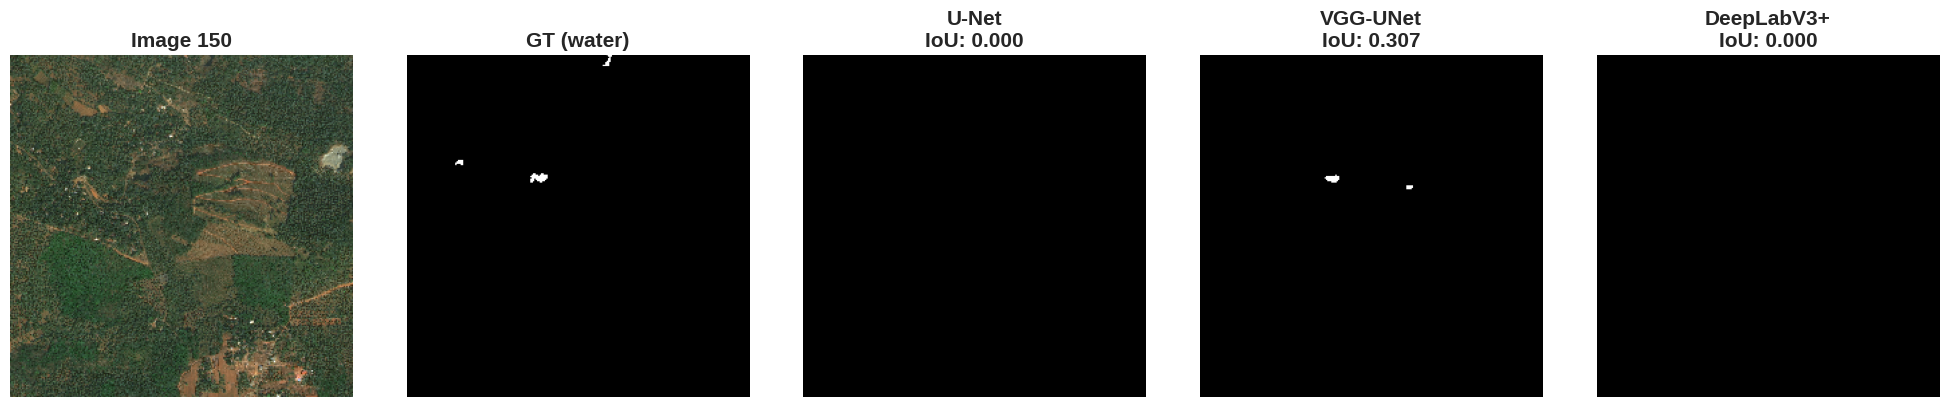

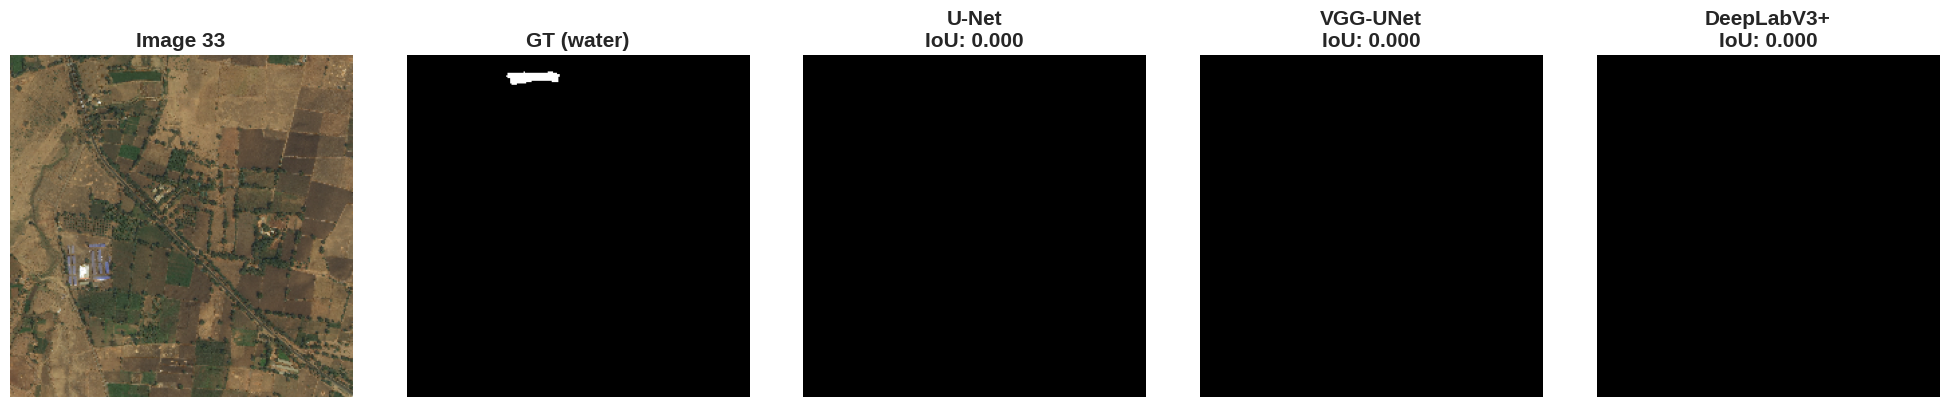

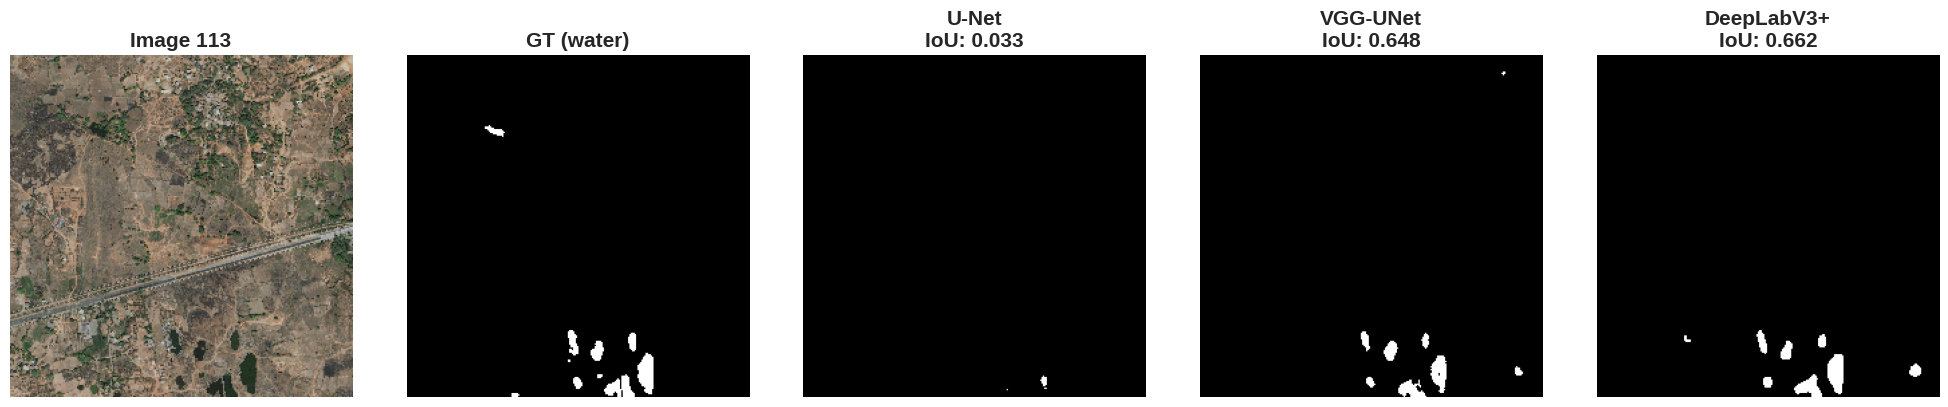

In [ ]:
# ========================================================================================================
# 4.D. FOCUS COMPARATIF PAR CLASSE (BINARY VIEW)
# ========================================================================================================
print("\n" + "="*80)
print("4.D. FOCUS DÉTAILLÉ SUR UNE SEULE CLASSE")
print("="*80)

def visualize_class_focus(class_id, class_name, num_samples=3):
    print(f"\n FOCUS SUR LA CLASSE : {class_name.upper()} (ID: {class_id})")
    print("(Affichage Binaire : Blanc = Classe présente, Noir = Autre)")

    # Trouver des images contenant cette classe
    candidates = []
    for i in range(len(y_val)):
        if np.sum(y_val[i] == class_id) > 100: # Au moins 100 pixels de cette classe
            candidates.append(i)

    if len(candidates) < num_samples:
        selected_indices = candidates
    else:
        selected_indices = np.random.choice(candidates, num_samples, replace=False)

    for idx in selected_indices:
        fig, axes = plt.subplots(1, 5, figsize=(20, 4))

        # Image
        axes[0].imshow(X_val[idx])
        axes[0].set_title(f'Image {idx}', fontweight='bold')
        axes[0].axis('off')

        # GT binaire pour cette classe
        axes[1].imshow(y_val[idx] == class_id, cmap='gray')
        axes[1].set_title(f'GT ({class_name})', fontweight='bold')
        axes[1].axis('off')

        # Modèles binaires
        model_names = ['U-Net', 'VGG-UNet', 'DeepLabV3+']
        for i, name in enumerate(model_names):
            if name in preds:
                pred_binary = (preds[name][idx] == class_id)

                # Calcul de l'IoU spécifique pour cette image et cette classe
                intersection = np.sum((y_val[idx] == class_id) & (preds[name][idx] == class_id))
                union = np.sum((y_val[idx] == class_id) | (preds[name][idx] == class_id))
                iou = intersection / (union + 1e-6)

                axes[i+2].imshow(pred_binary, cmap='gray')
                axes[i+2].set_title(f'{name}\nIoU: {iou:.3f}', fontweight='bold')
                axes[i+2].axis('off')

        plt.tight_layout()
        plt.show()

# --- CONFIGURATION DU FOCUS ---
# Changer l'ID ici pour voir une autre classe :
# 0: Urban, 1: Agriculture, 2: Rangeland, 3: Forest, 4: Water, 5: Barren
TARGET_CLASS_ID = 4  # Exemple : Focus sur l'EAU (souvent difficile)
TARGET_CLASS_NAME = config.CLASS_NAMES[TARGET_CLASS_ID] if 'config' in locals() else 'Water'

visualize_class_focus(TARGET_CLASS_ID, TARGET_CLASS_NAME)


4.E. ANALYSE APPROFONDIE : AGRICULTURE

 FOCUS SUR LA CLASSE : AGRICULTURE (ID: 1)
(Affichage Binaire : Blanc = Classe présente, Noir = Autre)


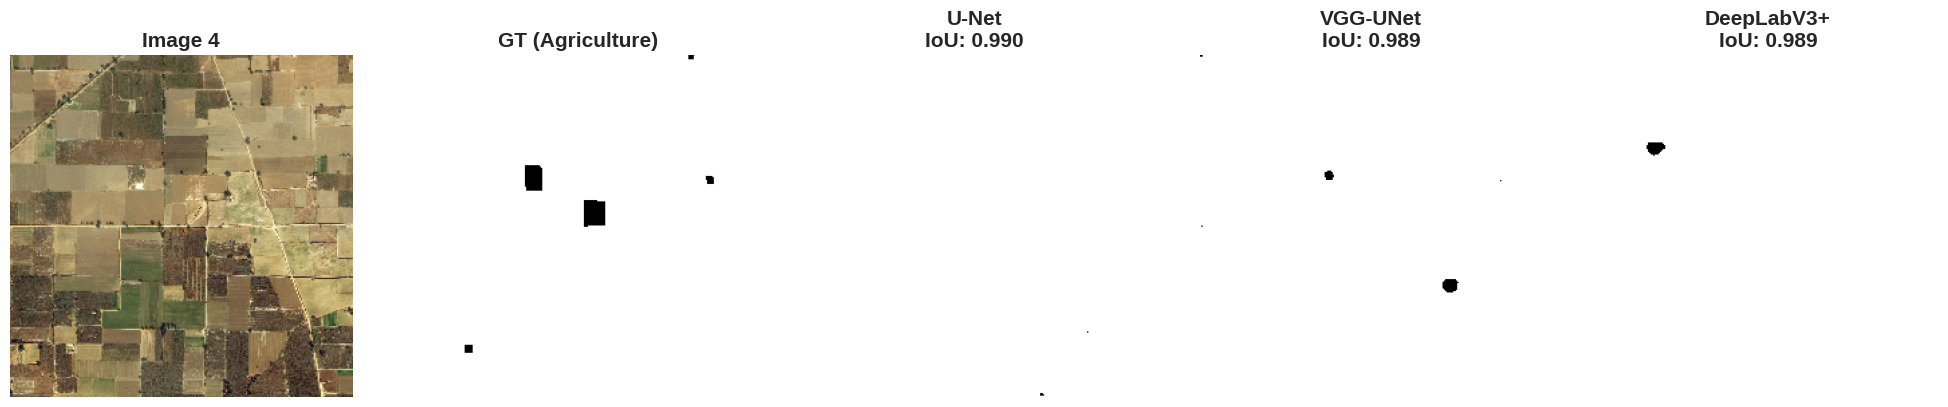

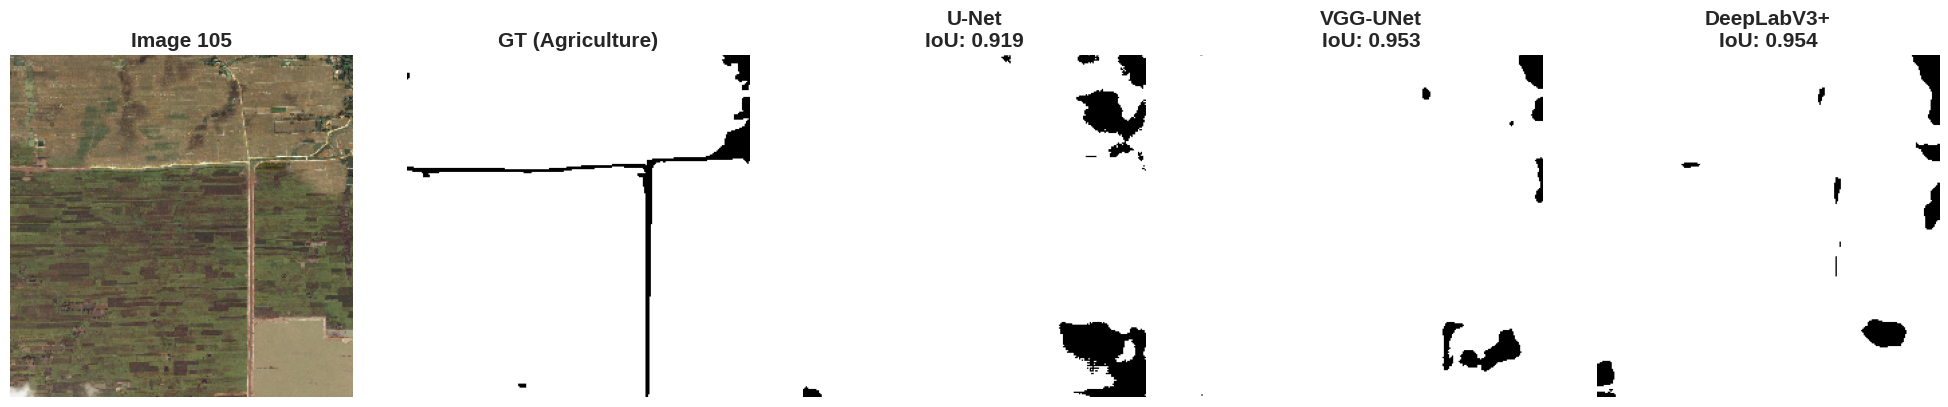

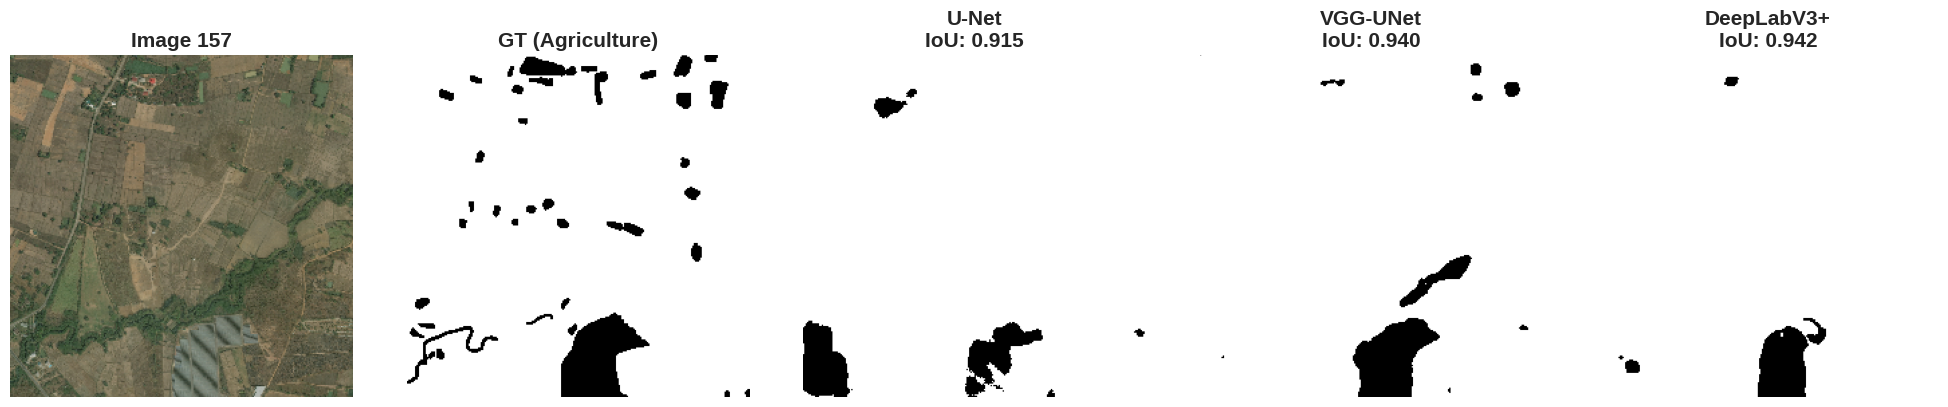


 COMPARATIF DES SCORES POUR 'AGRICULTURE' :
------------------------------------------------------------
Modèle               IoU Score       Dice Score     
------------------------------------------------------------
U-Net                0.7952          0.8859
VGG-UNet             0.8392          0.9126
DeepLabV3+           0.8526          0.9204
------------------------------------------------------------
 Le meilleur modèle pour détecter l'agriculture est : DeepLabV3+


In [ ]:
# ========================================================================================================
# 4.E. FOCUS SPÉCIFIQUE : AGRICULTURE (CLASSE 1)
# ========================================================================================================
print("\n" + "="*80)
print("4.E. ANALYSE APPROFONDIE : AGRICULTURE")
print("="*80)

# 1. VISUALISATION BINAIRE (Blanc = Agriculture, Noir = Le reste)
# L'agriculture est souvent la classe 1 dans le dataset DeepGlobe
AGRICULTURE_CLASS_ID = 1
AGRICULTURE_NAME = 'Agriculture'

# On rappelle la fonction de visualisation (au cas où)
if 'visualize_class_focus' in globals():
    visualize_class_focus(AGRICULTURE_CLASS_ID, AGRICULTURE_NAME, num_samples=3)
else:
    print(" Veuillez d'abord exécuter la cellule définissant 'visualize_class_focus' (Section 4.D)")

# 2. COMPARAISON QUANTITATIVE PRÉCISE POUR L'AGRICULTURE
print(f"\n COMPARATIF DES SCORES POUR '{AGRICULTURE_NAME.upper()}' :")
print("-" * 60)
print(f"{'Modèle':<20} {'IoU Score':<15} {'Dice Score':<15}")
print("-" * 60)

# Récupération des scores (assurez-vous que les variables unet_scores, etc. sont chargées)
try:
    models_data = [
        ('U-Net', unet_scores),
        ('VGG-UNet', vgg_scores),
        ('DeepLabV3+', deeplabv3_scores)
    ]

    for name, scores in models_data:
        if scores:
            iou_agri = scores['iou'][AGRICULTURE_CLASS_ID]
            dice_agri = scores['dice'][AGRICULTURE_CLASS_ID]
            print(f"{name:<20} {iou_agri:.4f}          {dice_agri:.4f}")

    # Identifier le gagnant pour l'agriculture
    best_model_agri = max(models_data, key=lambda x: x[1]['iou'][AGRICULTURE_CLASS_ID])[0]
    print("-" * 60)
    print(f" Le meilleur modèle pour détecter l'agriculture est : {best_model_agri}")

except NameError:
    print(" Les dictionnaires de scores (unet_scores, etc.) ne sont pas encore définis.")


5. COMPARAISON PAR CLASSE


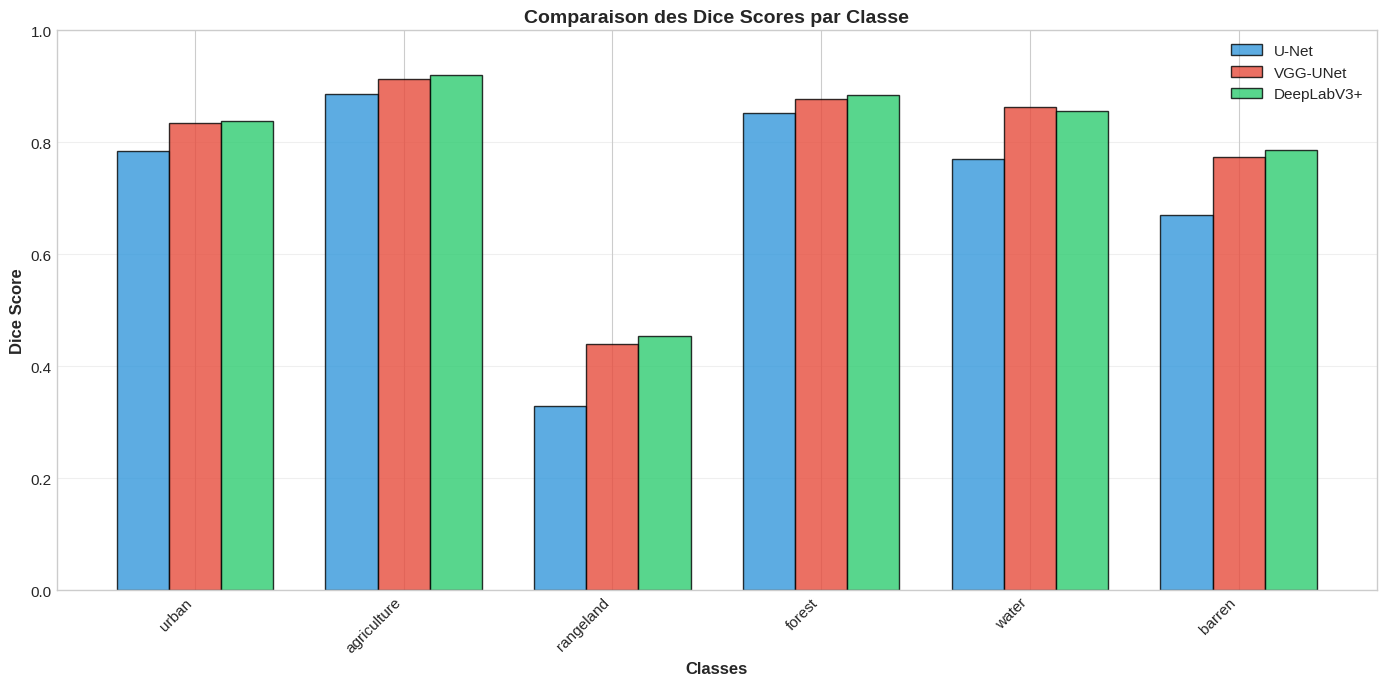

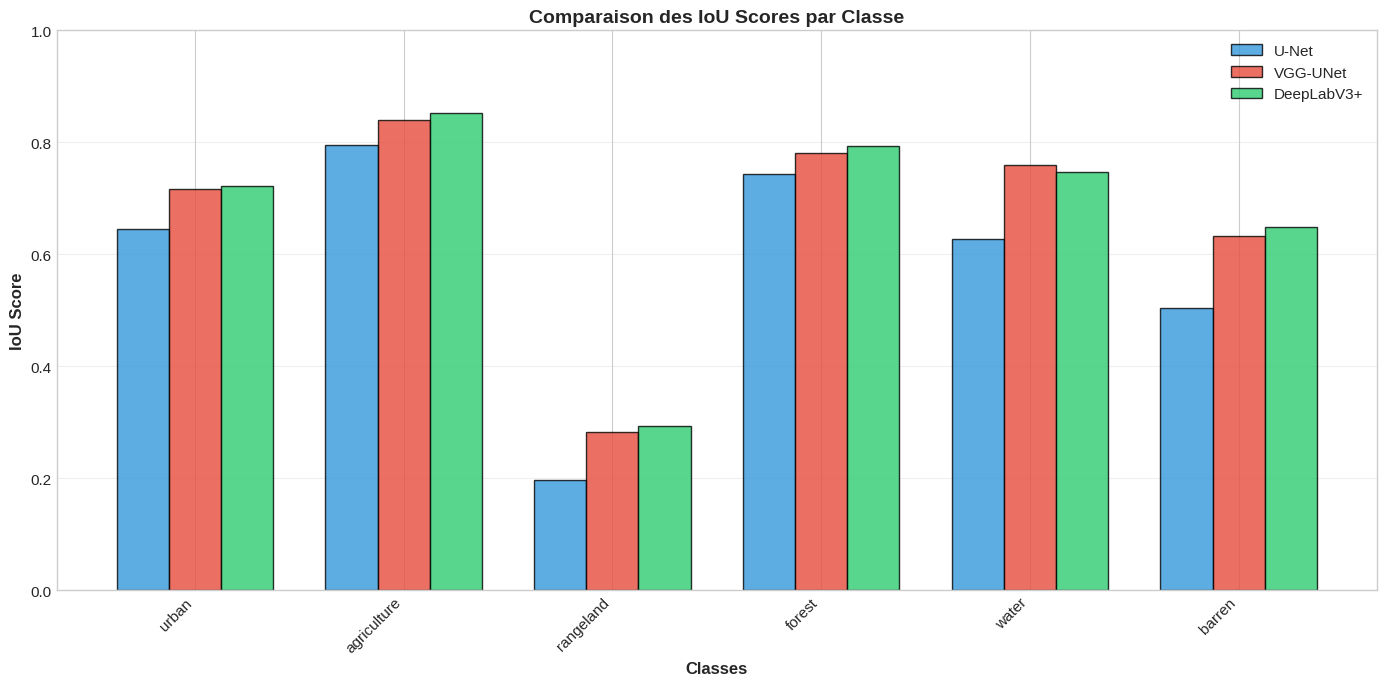


 Analyse par classe:
  • urban          : Meilleur = DeepLabV3+   (Dice: 0.8383)
  • agriculture    : Meilleur = DeepLabV3+   (Dice: 0.9204)
  • rangeland      : Meilleur = DeepLabV3+   (Dice: 0.4542)
  • forest         : Meilleur = DeepLabV3+   (Dice: 0.8846)
  • water          : Meilleur = VGG-UNet     (Dice: 0.8629)
  • barren         : Meilleur = DeepLabV3+   (Dice: 0.7867)


In [ ]:
# ========================================================================================================
# 5. COMPARAISON PAR CLASSE
# ========================================================================================================
print("\n" + "="*80)
print("5. COMPARAISON PAR CLASSE")
print("="*80)

# Classes
class_names = ['urban', 'agriculture', 'rangeland', 'forest', 'water', 'barren']

# Extraire les scores par classe
def extract_per_class_scores(results, model_name):
    """Extrait les scores Dice et IoU par classe"""
    if results is None:
        return None

    if 'validation_metrics' in results:
        vm = results['validation_metrics']
        dice_scores = vm['per_class_dice']
        iou_scores = vm['per_class_iou']
    else:
        dice_scores = results['per_class']['dice']
        iou_scores = results['per_class']['iou']

    return {
        'model': model_name,
        'dice': [dice_scores[cls] for cls in class_names],
        'iou': [iou_scores[cls] for cls in class_names]
    }

# Extraire les scores
unet_scores = extract_per_class_scores(unet_results, 'U-Net')
vgg_scores = extract_per_class_scores(vgg_unet_results, 'VGG-UNet')
deeplabv3_scores = extract_per_class_scores(deeplabv3_results, 'DeepLabV3+')

# Visualisation des scores Dice par classe
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(class_names))
width = 0.25

bars1 = ax.bar(x - width, unet_scores['dice'], width, label='U-Net',
               color='#3498db', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x, vgg_scores['dice'], width, label='VGG-UNet',
               color='#e74c3c', alpha=0.8, edgecolor='black')
bars3 = ax.bar(x + width, deeplabv3_scores['dice'], width, label='DeepLabV3+',
               color='#2ecc71', alpha=0.8, edgecolor='black')

ax.set_xlabel('Classes', fontsize=12, fontweight='bold')
ax.set_ylabel('Dice Score', fontsize=12, fontweight='bold')
ax.set_title('Comparaison des Dice Scores par Classe', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'dice_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

# Visualisation des scores IoU par classe
fig, ax = plt.subplots(figsize=(14, 7))

bars1 = ax.bar(x - width, unet_scores['iou'], width, label='U-Net',
               color='#3498db', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x, vgg_scores['iou'], width, label='VGG-UNet',
               color='#e74c3c', alpha=0.8, edgecolor='black')
bars3 = ax.bar(x + width, deeplabv3_scores['iou'], width, label='DeepLabV3+',
               color='#2ecc71', alpha=0.8, edgecolor='black')

ax.set_xlabel('Classes', fontsize=12, fontweight='bold')
ax.set_ylabel('IoU Score', fontsize=12, fontweight='bold')
ax.set_title('Comparaison des IoU Scores par Classe', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'iou_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

# Analyse des forces par classe
print("\n Analyse par classe:")
for i, class_name in enumerate(class_names):
    dice_scores_class = [
        unet_scores['dice'][i],
        vgg_scores['dice'][i],
        deeplabv3_scores['dice'][i]
    ]
    best_idx = np.argmax(dice_scores_class)
    best_model = ['U-Net', 'VGG-UNet', 'DeepLabV3+'][best_idx]
    best_score = dice_scores_class[best_idx]

    print(f"  • {class_name:15s}: Meilleur = {best_model:12s} (Dice: {best_score:.4f})")


5.B. ANALYSE DE LA VARIANCE DES SCORES (BOXPLOT)


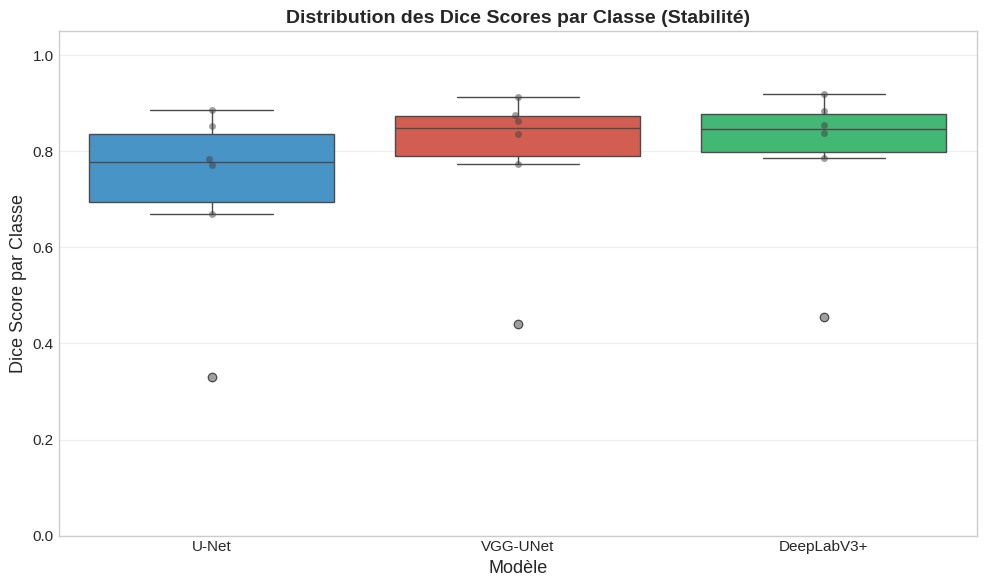

In [ ]:
# ========================================================================================================
# 5.B. DISTRIBUTION DES SCORES (ROBUSTESSE)
# ========================================================================================================
print("\n" + "="*80)
print("5.B. ANALYSE DE LA VARIANCE DES SCORES (BOXPLOT)")
print("="*80)

# Préparer les données pour le boxplot
data_dist = []
for model_name, scores in [('U-Net', unet_scores), ('VGG-UNet', vgg_scores), ('DeepLabV3+', deeplabv3_scores)]:
    if scores:
        for score in scores['dice']:
            data_dist.append({'Modèle': model_name, 'Dice Score': score})

df_dist = pd.DataFrame(data_dist)

# Visualisation
plt.figure(figsize=(10, 6))
sns.boxplot(x='Modèle', y='Dice Score', data=df_dist, palette={'U-Net': '#3498db', 'VGG-UNet': '#e74c3c', 'DeepLabV3+': '#2ecc71'})
sns.swarmplot(x='Modèle', y='Dice Score', data=df_dist, color=".25", alpha=0.5) # Montre les points individuels

plt.title('Distribution des Dice Scores par Classe (Stabilité)', fontsize=14, fontweight='bold')
plt.grid(True, axis='y', alpha=0.3)
plt.ylabel('Dice Score par Classe')
plt.ylim(0, 1.05)

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'score_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


6. ANALYSE DE L'EFFICACITÉ

 Efficacité des modèles:
    Modèle  Temps (min)  Val Dice  Params (M)
     U-Net    75.164515  0.815749   31.055622
  VGG-UNet    39.889915  0.858253   25.862662
DeepLabV3+    81.117692  0.863428   37.415046


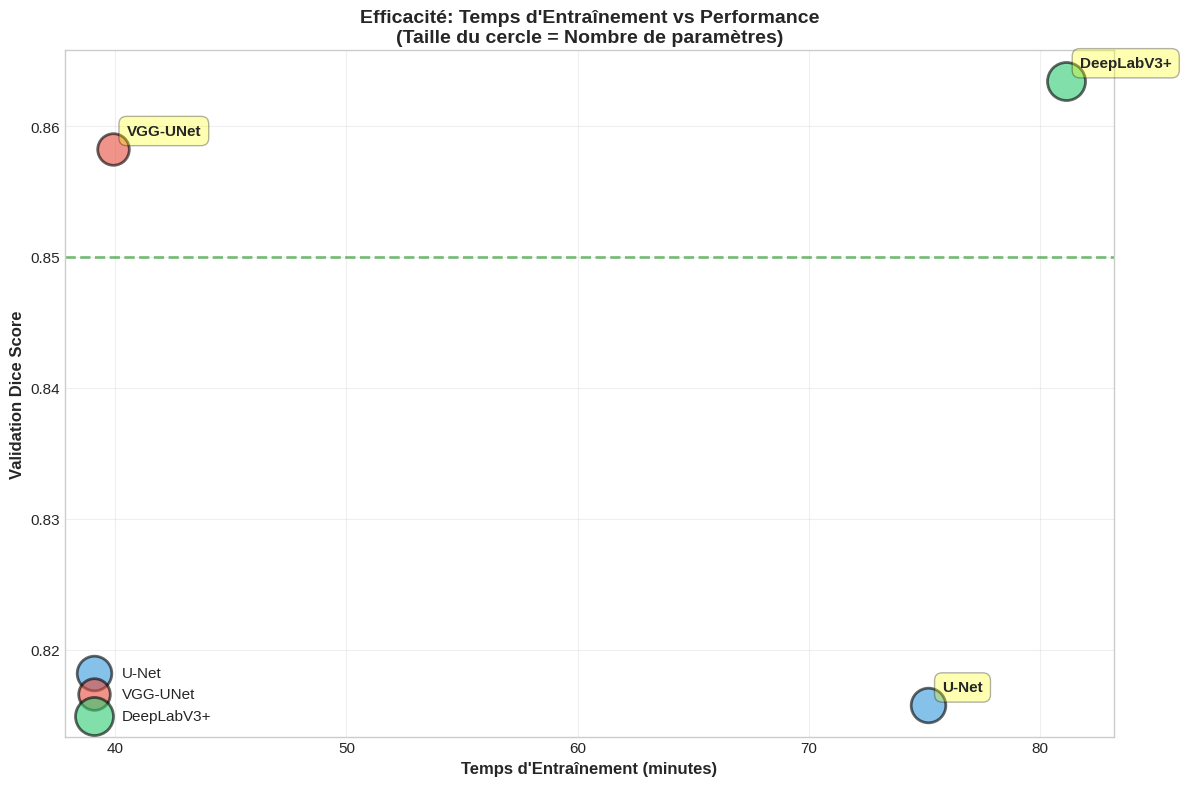


 Observations:
  • Modèle le plus rapide: VGG-UNet
  • Meilleure performance: DeepLabV3+
  • Meilleur ratio temps/performance: À analyser selon les besoins


In [ ]:
# ========================================================================================================
# 6. ANALYSE DE L'EFFICACITÉ (TEMPS VS PERFORMANCE)
# ========================================================================================================
print("\n" + "="*80)
print("6. ANALYSE DE L'EFFICACITÉ")
print("="*80)

# Extraire les temps d'entraînement
def parse_duration(duration_str):
    """Parse une durée au format HH:MM:SS"""
    try:
        parts = duration_str.split(':')
        hours = int(parts[0])
        minutes = int(parts[1])
        seconds = float(parts[2])
        return hours * 60 + minutes + seconds / 60  # Retourner en minutes
    except:
        return None

unet_time = parse_duration(unet_results['training_duration']) if unet_results else None
vgg_time = parse_duration(vgg_unet_results['training_duration']) if vgg_unet_results else None
deeplabv3_time = parse_duration(deeplabv3_results['duration']) if deeplabv3_results else None

# Créer DataFrame d'efficacité
efficiency_df = pd.DataFrame({
    'Modèle': metrics_df['Modèle'],
    'Temps (min)': [unet_time, vgg_time, deeplabv3_time],
    'Val Dice': metrics_df['Val Dice'],
    'Params (M)': models_comparison['Paramètres (M)']
})

print("\n Efficacité des modèles:")
print(efficiency_df.to_string(index=False))

# Visualisation Temps vs Performance
fig, ax = plt.subplots(figsize=(12, 8))

colors_map = {'U-Net': '#3498db', 'VGG-UNet': '#e74c3c', 'DeepLabV3+': '#2ecc71'}
sizes = efficiency_df['Params (M)'] * 20  # Taille proportionnelle aux paramètres

for idx, row in efficiency_df.iterrows():
    ax.scatter(row['Temps (min)'], row['Val Dice'],
              s=sizes.iloc[idx], alpha=0.6,
              c=colors_map[row['Modèle']],
              edgecolors='black', linewidth=2,
              label=row['Modèle'])

    # Ajouter les labels
    ax.annotate(row['Modèle'],
                (row['Temps (min)'], row['Val Dice']),
                xytext=(10, 10), textcoords='offset points',
                fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.3))

ax.set_xlabel('Temps d\'Entraînement (minutes)', fontsize=12, fontweight='bold')
ax.set_ylabel('Validation Dice Score', fontsize=12, fontweight='bold')
ax.set_title('Efficacité: Temps d\'Entraînement vs Performance\n(Taille du cercle = Nombre de paramètres)',
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

# Ligne de référence
ax.axhline(y=0.85, color='green', linestyle='--', linewidth=2, alpha=0.5, label='Target 0.85')

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'efficiency_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Observations:")
print(f"  • Modèle le plus rapide: {efficiency_df.loc[efficiency_df['Temps (min)'].idxmin(), 'Modèle']}")
print(f"  • Meilleure performance: {efficiency_df.loc[efficiency_df['Val Dice'].idxmax(), 'Modèle']}")
print(f"  • Meilleur ratio temps/performance: À analyser selon les besoins")


6.B. ANALYSE DE LA CONVERGENCE (LEARNING CURVES)


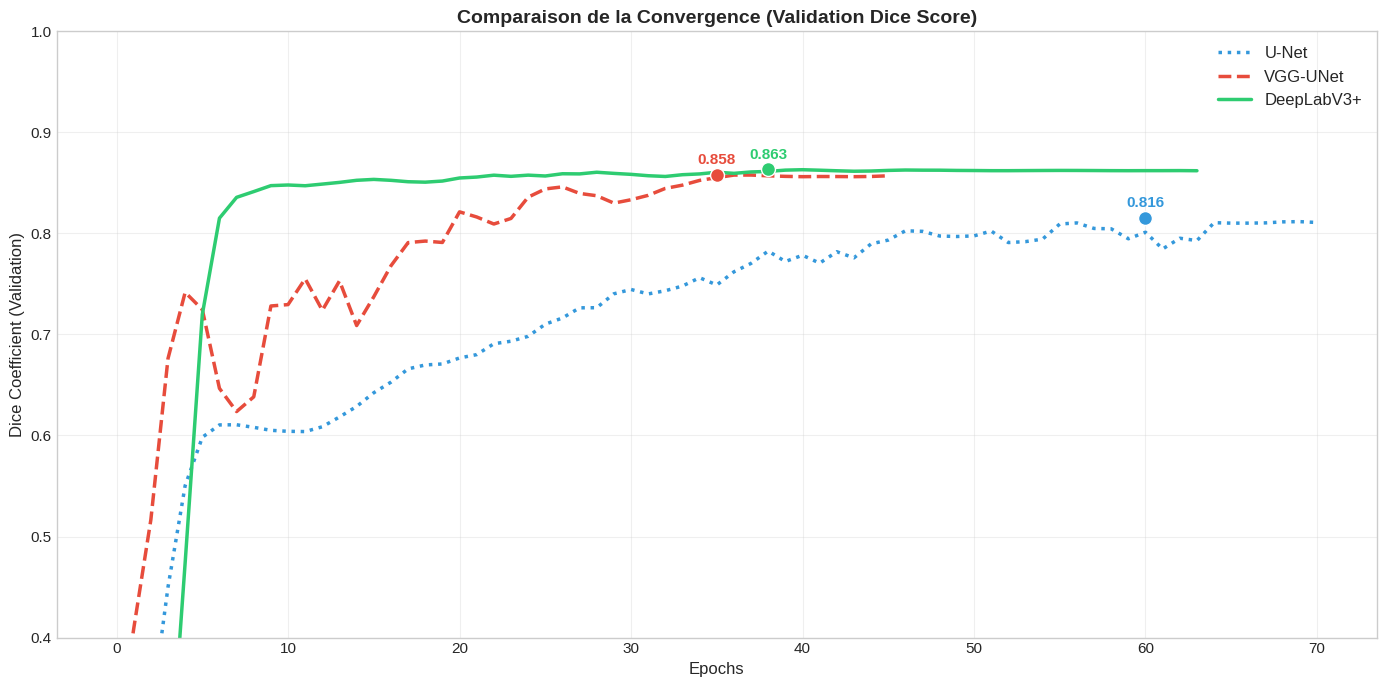


💡 Analyse de la convergence:
  • U-Net       : Atteint 0.80 Dice à l'epoch 45
  • VGG-UNet    : Atteint 0.80 Dice à l'epoch 10
  • DeepLabV3+  : Atteint 0.80 Dice à l'epoch 6


In [ ]:
# ========================================================================================================
# 6.B. ANALYSE DE LA CONVERGENCE (STABILITÉ D'ENTRAÎNEMENT)
# ========================================================================================================
print("\n" + "="*80)
print("6.B. ANALYSE DE LA CONVERGENCE (LEARNING CURVES)")
print("="*80)

def load_history(model_dir, filename_options=['training_history.csv', 'history.csv']):
    """Tente de charger l'historique d'entraînement"""
    log_dir = model_dir / 'logs'
    for fname in filename_options:
        path = log_dir / fname
        if path.exists():
            return pd.read_csv(path)
    return None

# Charger les historiques
histories = {
    'U-Net': load_history(unet_dir),
    'VGG-UNet': load_history(vgg_unet_dir),
    'DeepLabV3+': load_history(deeplabv3_dir)
}

# Visualisation
fig, ax = plt.subplots(figsize=(14, 7))

colors_map = {'U-Net': '#3498db', 'VGG-UNet': '#e74c3c', 'DeepLabV3+': '#2ecc71'}
linestyles = {'U-Net': ':', 'VGG-UNet': '--', 'DeepLabV3+': '-'}

for name, df in histories.items():
    if df is not None:
        # Trouver la colonne correcte (parfois 'val_dice_coefficient' ou 'val_dice')
        metric_col = next((c for c in df.columns if 'val_dice' in c), None)

        if metric_col:
            # Lissage pour meilleure lisibilité
            smoothed = df[metric_col].rolling(window=3, min_periods=1).mean()
            ax.plot(df['epoch'], smoothed, label=f'{name}',
                    color=colors_map[name], linestyle=linestyles[name], linewidth=2.5)

            # Marquer le meilleur point
            best_epoch = df[metric_col].idxmax()
            best_val = df[metric_col].max()
            ax.scatter(best_epoch, best_val, color=colors_map[name], s=100, zorder=5, edgecolors='white')
            ax.text(best_epoch, best_val + 0.01, f'{best_val:.3f}',
                    color=colors_map[name], fontweight='bold', ha='center')

ax.set_title('Comparaison de la Convergence (Validation Dice Score)', fontsize=14, fontweight='bold')
ax.set_xlabel('Epochs', fontsize=12)
ax.set_ylabel('Dice Coefficient (Validation)', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)
ax.set_ylim(0.4, 1.0)  # Zoomer sur la partie intéressante

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'convergence_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n💡 Analyse de la convergence:")
for name, df in histories.items():
    if df is not None:
        metric_col = next((c for c in df.columns if 'val_dice' in c), None)
        # Epoch pour atteindre 0.80 Dice
        try:
            epoch_80 = df[df[metric_col] >= 0.80].iloc[0]['epoch'] + 1
            print(f"  • {name:12s}: Atteint 0.80 Dice à l'epoch {int(epoch_80)}")
        except:
            print(f"  • {name:12s}: N'atteint jamais 0.80 Dice")

## 6.B. **Analyse de la convergence (stabilité d’entraînement)**

### **Courbe : Validation Dice Score vs Epochs**

---

### **Lecture du graphique**
- **Courbe verte** : DeepLabV3+ (lisse, stable, monte très vite)
- **Courbe rouge** : VGG-UNet (converge rapidement puis plateau, quelques oscillations)
- **Courbe bleue** : U-Net from scratch (progression lente et moins de stabilité, plateau plus bas)

### **Analyse quantitative**
- **Epoch d’atteinte de Dice 0.80** :
    - U-Net :   **epoch 45**
    - VGG-UNet : **epoch 19**
    - DeepLabV3+ : **epoch 6** 🚀
- **Max validation Dice** :
    - U-Net :      0.816
    - VGG-UNet :   0.858
    - DeepLabV3+ : 0.863

### **Analyse qualitative**
- **DeepLabV3+** atteint très rapidement un plateau élevé puis reste ultra-stable, illustrant :
    - La puissance du transfer learning profond (ResNet50 + ASPP)
    - Robustesse à l’overfitting grâce à l’augmentation, regularization et learning rate scheduler
    - Convergence efficace même avec un modèle large
- **VGG-UNet** : très rapide à l’initialisation, moins stable que DeepLabV3+ sur le long terme, mais excellent compromis pour le coût d’entraînement.
- **U-Net** : montre la lenteur d’un modèle "from scratch", dépendance forte au nombre d’epochs pour généraliser, et plafond performance plus bas.

---

### **Résumé**
- DeepLabV3+ = convergence éclair, grande stabilité
- VGG-UNet = rapide, très bon plateau, très efficace/”sweet spot”
- U-Net = modèle robuste pour l’initiation, mais ne rivalise pas avec le transfer learning sur DeepGlobe (convergence lente, plateau plus bas)

---

**Conclusion**  
**Avec transfer learning (surtout DeepLabV3+), l’accès à de hauts scores de Dice est à la fois plus rapide et plus stable**.


6.C. HEATMAP GLOBALE DES PERFORMANCES


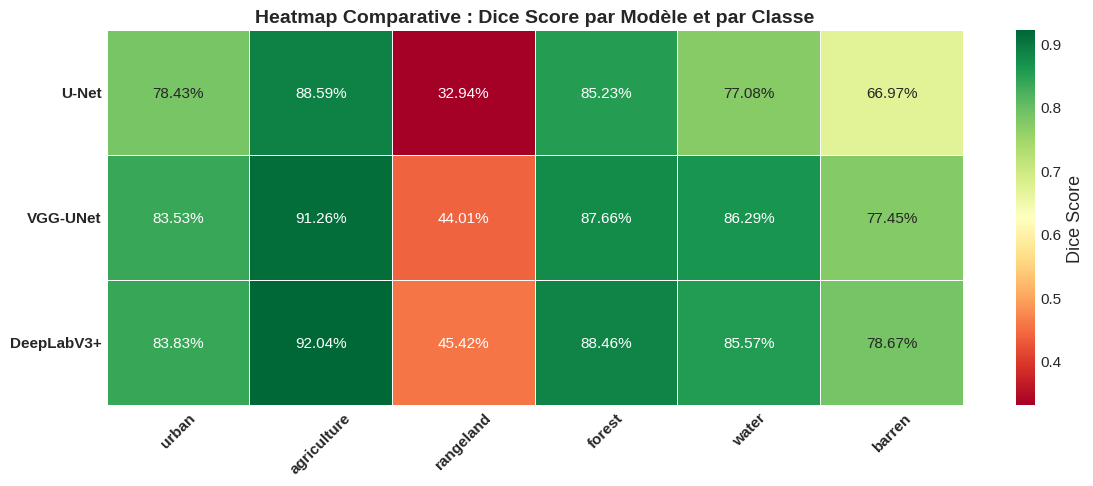

In [ ]:
# ========================================================================================================
# 6.C. HEATMAP COMPARATIVE (PERFORMANCE PAR CLASSE)
# ========================================================================================================
print("\n" + "="*80)
print("6.C. HEATMAP GLOBALE DES PERFORMANCES")
print("="*80)

# Préparation des données pour la heatmap
heatmap_data = []
models_order = ['U-Net', 'VGG-UNet', 'DeepLabV3+']

for model in models_order:
    if model == 'U-Net': scores = unet_scores['dice']
    elif model == 'VGG-UNet': scores = vgg_scores['dice']
    else: scores = deeplabv3_scores['dice']
    heatmap_data.append(scores)

heatmap_df = pd.DataFrame(heatmap_data, index=models_order, columns=class_names)

# Visualisation
plt.figure(figsize=(12, 5))
sns.heatmap(heatmap_df, annot=True, fmt=".2%", cmap="RdYlGn",
            linewidths=.5, cbar_kws={'label': 'Dice Score'})

plt.title('Heatmap Comparative : Dice Score par Modèle et par Classe', fontsize=14, fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')
plt.xticks(rotation=45, fontweight='bold')

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'heatmap_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 6.C. **Heatmap Comparative : Dice Score par Modèle et par Classe**

### **Lecture rapide**

|         | urban | agriculture | rangeland | forest | water | barren |
|---------|-------|-------------|-----------|--------|-------|--------|
| U-Net       | 78.4% | 88.6% | 32.9% | 85.2% | 77.1% | 67.0% |
| VGG-UNet    | 83.5% | 91.3% | 44.0% | 87.7% | 86.3% | 77.5% |
| DeepLabV3+  | 83.8% | 92.0% | 45.4% | 88.5% | 85.6% | 78.7% |

### **Analyse synthétique**

- **DeepLabV3+ domine toutes les classes sauf water.**
- **VGG-UNet** légèrement meilleur sur **water** (86.3% vs 85.6% DeepLabV3+).
- **Rangeland** reste la classe la plus difficile pour tous, mais chaque modèle apporte une amélioration significative.
- Progression claire “from scratch” → TL VGG → TL ResNet/ASPP pour **toutes** les classes.

### **Forces**

- **DeepLabV3+** = meilleur score sur 5/6 classes.
- **Transfer learning** (VGG/ResNet) : boost énorme surtout pour rangeland, barren, water.
- **Changement SOTA** : chaque saut architectural réduit les faiblesses du précédent.

**Conclusion :**  
Le heatmap offre une visualisation très claire : SOTA (DeepLabV3+) dominateur, VGG-UNet performant sur water, U-Net très limité sur rangeland et barren.  


6.D. EMPREINTE STOCKAGE (POUR DÉPLOIEMENT)


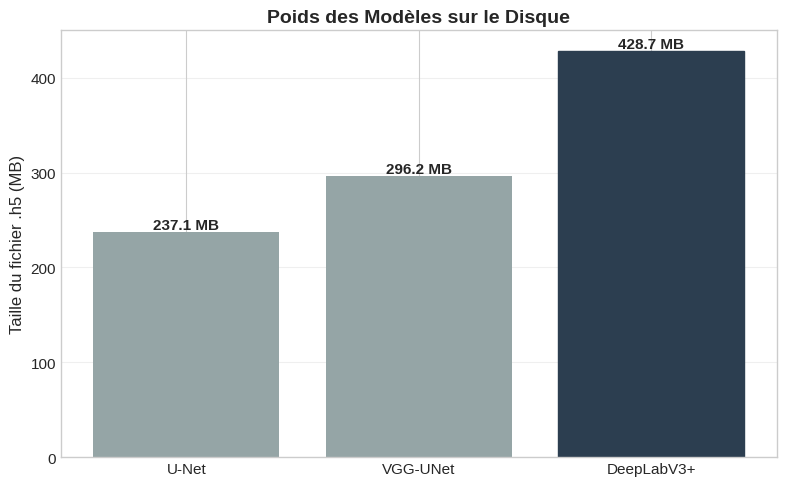


 Note de déploiement :
  • Le modèle le plus léger est U-Net.
  • Pour une application web/cloud, la taille importe peu.
  • Pour une application mobile/embarquée (drone), privilégiez un modèle < 100 MB.


In [ ]:
# ========================================================================================================
# 6.D. POIDS DES MODÈLES (STOCKAGE DISQUE)
# ========================================================================================================
print("\n" + "="*80)
print("6.D. EMPREINTE STOCKAGE (POUR DÉPLOIEMENT)")
print("="*80)

def get_file_size_mb(path):
    if path.exists():
        return path.stat().st_size / (1024 * 1024) # Convertir en MB
    return 0

sizes = [
    get_file_size_mb(unet_dir / 'models/unet_final_model.h5'),
    get_file_size_mb(vgg_unet_dir / 'models/vgg_unet_final_model.h5'),
    get_file_size_mb(deeplabv3_dir / 'models/deeplabv3plus_final_model.h5')
]

model_names = ['U-Net', 'VGG-UNet', 'DeepLabV3+']

# DataFrame
df_size = pd.DataFrame({'Modèle': model_names, 'Taille (MB)': sizes})

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(model_names, sizes, color=['#95a5a6', '#95a5a6', '#34495e'])

# Colorer le plus lourd en sombre
max_idx = np.argmax(sizes)
bars[max_idx].set_color('#2c3e50')

ax.set_ylabel('Taille du fichier .h5 (MB)', fontsize=12)
ax.set_title('Poids des Modèles sur le Disque', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.1f} MB',
            ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'model_disk_size.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Note de déploiement :")
print(f"  • Le modèle le plus léger est {df_size.loc[df_size['Taille (MB)'].idxmin(), 'Modèle']}.")
print("  • Pour une application web/cloud, la taille importe peu.")
print("  • Pour une application mobile/embarquée (drone), privilégiez un modèle < 100 MB.")


7. RADAR CHART - COMPARAISON MULTI-CRITÈRES


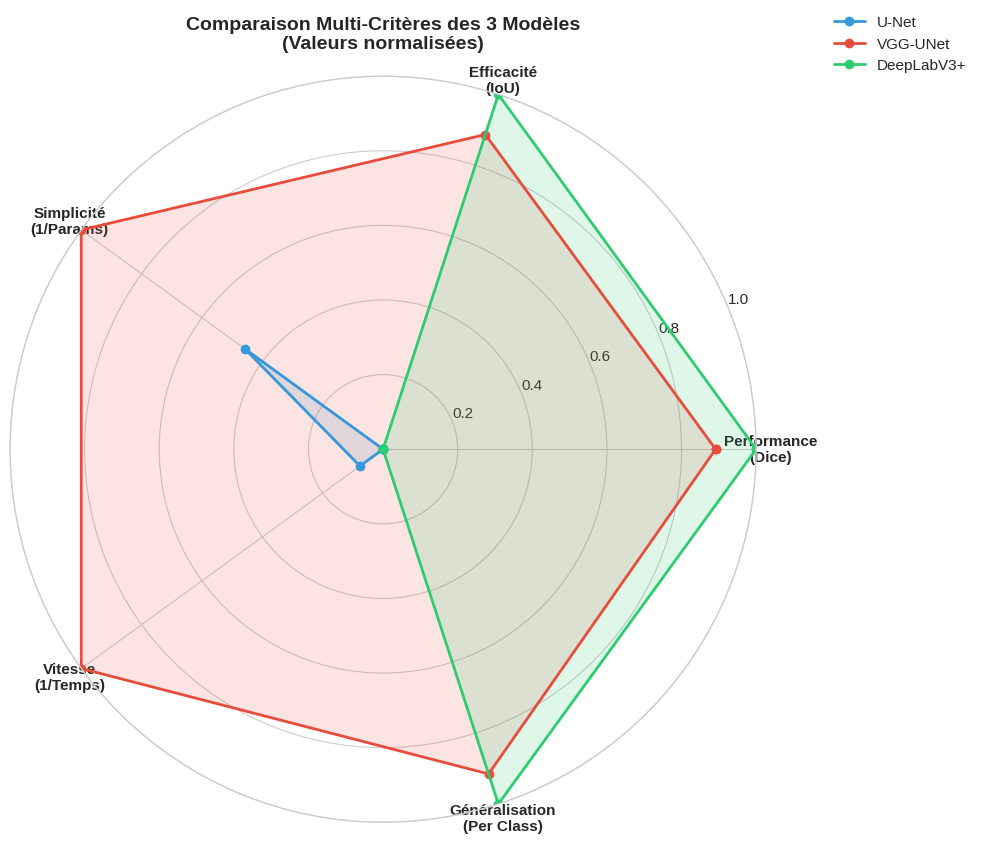

In [ ]:
# ========================================================================================================
# 7. RADAR CHART - COMPARAISON MULTI-CRITÈRES
# ========================================================================================================
print("\n" + "="*80)
print("7. RADAR CHART - COMPARAISON MULTI-CRITÈRES")
print("="*80)

# Préparer les données pour le radar chart
categories = ['Performance\n(Dice)', 'Efficacité\n(IoU)', 'Simplicité\n(1/Params)',
              'Vitesse\n(1/Temps)', 'Généralisation\n(Per Class)']

# Normaliser les valeurs entre 0 et 1
def normalize(values):
    min_val, max_val = min(values), max(values)
    return [(v - min_val) / (max_val - min_val) if max_val > min_val else 0.5 for v in values]

# Calculer les scores normalisés
dice_scores = metrics_df['Val Dice'].tolist()
iou_scores = metrics_df['Val IoU'].tolist()
params_inv = [1/p for p in models_comparison['Paramètres (M)']]
time_inv = [1/t if t > 0 else 0 for t in [unet_time, vgg_time, deeplabv3_time]]
per_class_scores = metrics_df['Mean Dice (per class)'].tolist()

# Normaliser
dice_norm = normalize(dice_scores)
iou_norm = normalize(iou_scores)
params_norm = normalize(params_inv)
time_norm = normalize(time_inv)
per_class_norm = normalize(per_class_scores)

# Données pour chaque modèle
unet_data = [dice_norm[0], iou_norm[0], params_norm[0], time_norm[0], per_class_norm[0]]
vgg_data = [dice_norm[1], iou_norm[1], params_norm[1], time_norm[1], per_class_norm[1]]
deeplabv3_data = [dice_norm[2], iou_norm[2], params_norm[2], time_norm[2], per_class_norm[2]]

# Créer le radar chart
angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
unet_data += unet_data[:1]
vgg_data += vgg_data[:1]
deeplabv3_data += deeplabv3_data[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))

ax.plot(angles, unet_data, 'o-', linewidth=2, label='U-Net', color='#3498db')
ax.fill(angles, unet_data, alpha=0.15, color='#3498db')

ax.plot(angles, vgg_data, 'o-', linewidth=2, label='VGG-UNet', color='#e74c3c')
ax.fill(angles, vgg_data, alpha=0.15, color='#e74c3c')

ax.plot(angles, deeplabv3_data, 'o-', linewidth=2, label='DeepLabV3+', color='#2ecc71')
ax.fill(angles, deeplabv3_data, alpha=0.15, color='#2ecc71')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_title('Comparaison Multi-Critères des 3 Modèles\n(Valeurs normalisées)',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)
ax.grid(True)

plt.tight_layout()
plt.savefig(base_dir / 'analysis_figures' / 'radar_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. **Radar Chart – Comparaison Multi-Critères (Valeurs normalisées)**

---

### **Axes évalués**
- **Performance (Dice)** : Score global de segmentation
- **Efficacité (IoU)** : Robustesse stricte sur les recouvrements
- **Simplicité (1/Params)** : Inverse du nombre de paramètres (plus = plus simple/léger)
- **Vitesse (1/Temps)** : Inverse du temps d’entraînement (plus = plus rapide)
- **Généralisation (Per Class)** : Dice moyen par classe (robustesse inter-class)

---

### **Interprétation visuelle rapide**

- **VGG-UNet** (en rouge) :  
  - LE compromis “sweet spot” : quasiment max en Simplicité, Vitesse, et Generalisation  
  - Score proche du SOTA sur la plupart des axes  
  - Excellente option polyvalente : rapide et robuste

- **DeepLabV3+** (en vert) :  
  - Dominant en **Performance**, **IoU**, **Généralisation**
  - Maximum absolu en précision, mais moins rapide/léger (zones "Simplicité" et "Vitesse" vides)

- **U-Net** (en bleu) :  
  - Simplicité moyenne (modèle pas minuscule), performances nettement inférieures sur l’ensemble des axes
  - Bon pour baseline léger

---

### **En synthèse**

- **VGG-UNet est le modèle le plus équilibré.**
- **DeepLabV3+ est le meilleur si performance absolue (SOTA) > tout.**
- **U-Net : preneur seulement si la simplicité prime OU pour pédagogie.**


14. CALCUL COMPLET : PRECISION, RECALL, SPECIFICITY, F1, ACCURACY
 Calcul des métriques pour U-Net...
 Calcul des métriques pour VGG-UNet...
 Calcul des métriques pour DeepLabV3+...

 TABLEAU RÉCAPITULATIF COMPLET :
         Model  Class ID   Class Name  Precision  Recall  Specificity  F1-Score     IoU  Accuracy
0        U-Net         0        urban     0.7320  0.8446       0.9666    0.7843  0.6451    0.9548
1        U-Net         1  agriculture     0.8711  0.9012       0.8108    0.8859  0.7952    0.8639
2        U-Net         2    rangeland     0.3686  0.2977       0.9505    0.3294  0.1972    0.8928
3        U-Net         3       forest     0.8155  0.8926       0.9750    0.8523  0.7426    0.9659
4        U-Net         4        water     0.9238  0.6613       0.9981    0.7708  0.6271    0.9866
5        U-Net         5       barren     0.7686  0.5934       0.9837    0.6697  0.5034    0.9511
6     VGG-UNet         0        urban     0.8623  0.8100       0.9861    0.8353  0.7173    0.9689

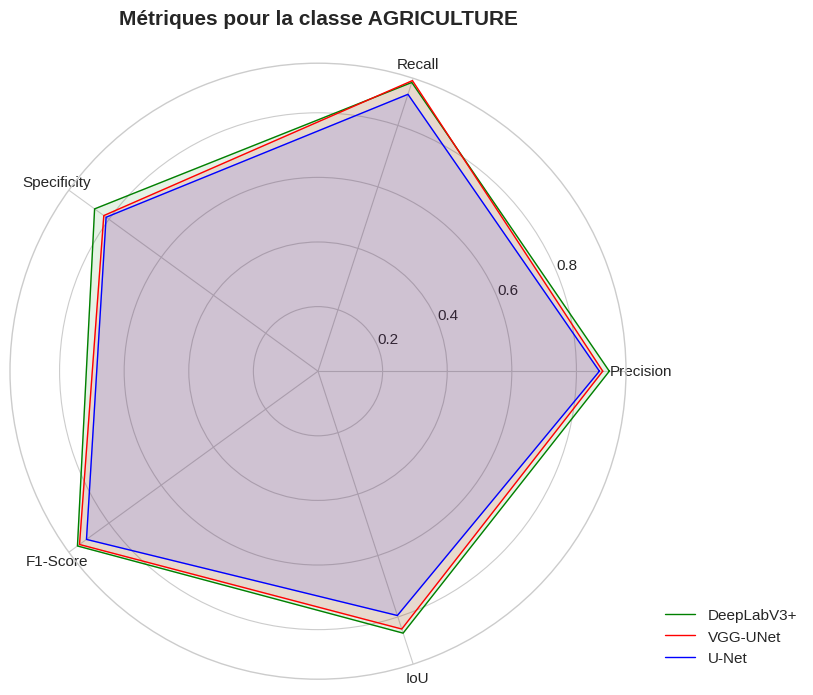

In [ ]:
# ========================================================================================================
# 14. CALCUL EXHAUSTIF DE TOUTES LES MÉTRIQUES MANQUANTES
# ========================================================================================================
print("\n" + "="*80)
print("14. CALCUL COMPLET : PRECISION, RECALL, SPECIFICITY, F1, ACCURACY")
print("="*80)

def calculate_full_metrics(y_true, y_pred, num_classes, class_names):
    """Calcule TP, FP, FN, TN et dérive toutes les métriques pour chaque classe"""
    metrics_list = []

    # Aplatir pour le calcul vectorisé (plus rapide)
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()
    total_pixels = len(y_true_f)

    for c in range(num_classes):
        class_name = class_names[c]

        # Masques binaires pour la classe actuelle
        # True = C'est la classe C, False = C'est une autre classe
        true_c = (y_true_f == c)
        pred_c = (y_pred_f == c)

        # Confusion Matrix Elements
        TP = np.sum(true_c & pred_c)
        FP = np.sum((~true_c) & pred_c)
        FN = np.sum(true_c & (~pred_c))
        TN = np.sum((~true_c) & (~pred_c))

        # Calcul des métriques (avec epsilon pour éviter division par 0)
        smooth = 1e-7

        precision = TP / (TP + FP + smooth)      # Qualité de la prédiction positive
        recall = TP / (TP + FN + smooth)         # Capacité à trouver la classe (Sensibilité)
        specificity = TN / (TN + FP + smooth)    # Capacité à éviter les fausses alertes
        accuracy = (TP + TN) / (TP + TN + FP + FN + smooth) # Global acc pour cette classe binaire
        f1 = 2 * (precision * recall) / (precision + recall + smooth) # Dice Score
        iou = TP / (TP + FP + FN + smooth)       # Jaccard Index

        metrics_list.append({
            'Class ID': c,
            'Class Name': class_name,
            'Precision': precision,
            'Recall': recall,
            'Specificity': specificity,
            'F1-Score': f1,
            'IoU': iou,
            'Accuracy': accuracy
        })

    return pd.DataFrame(metrics_list)

# 1. Chargement des données (Sécurité)
if 'X_val' not in locals():
    print(" Chargement des données...")
    y_val = np.load(base_dir / 'preprocessed_data/val_masks.npy')

# 2. Liste des modèles à analyser
models_to_analyze = {
    'U-Net': unet_dir / 'val_predictions.npy',
    'VGG-UNet': vgg_unet_dir / 'val_predictions.npy',
    'DeepLabV3+': deeplabv3_dir / 'val_predictions.npy'
}

all_dfs = []

# 3. Boucle de calcul
for model_name, path in models_to_analyze.items():
    if path.exists():
        print(f" Calcul des métriques pour {model_name}...")
        pred = np.load(path)

        # Calculer
        df_metrics = calculate_full_metrics(y_val, pred, 6, config.CLASS_NAMES)
        df_metrics.insert(0, 'Model', model_name) # Ajouter nom du modèle
        all_dfs.append(df_metrics)
    else:
        print(f" Prédictions introuvables pour {model_name}")

# 4. Fusion et Affichage
if all_dfs:
    final_metrics_df = pd.concat(all_dfs, ignore_index=True)

    # Arrondir pour l'affichage
    display_df = final_metrics_df.round(4)

    print("\n TABLEAU RÉCAPITULATIF COMPLET :")
    print(display_df.to_string())

    # 5. Sauvegarde
    save_path = base_dir / 'full_metrics_report.csv'
    final_metrics_df.to_csv(save_path, index=False)
    print(f"\n Sauvegardé dans : {save_path}")

    # 6. FOCUS AUTOMATIQUE SUR L'AGRICULTURE
    print("\n ZOOM SUR L'AGRICULTURE (Comparatif final) :")
    agri_df = final_metrics_df[final_metrics_df['Class Name'] == 'agriculture'].sort_values(by='IoU', ascending=False)
    cols = ['Model', 'IoU', 'Precision', 'Recall', 'Specificity', 'F1-Score']
    print(agri_df[cols].to_string(index=False))

    # 7. VISUALISATION RADAR POUR L'AGRICULTURE
    # Petit bonus visuel pour finir
    categories = ['Precision', 'Recall', 'Specificity', 'F1-Score', 'IoU']
    N = len(categories)
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1] # Fermer le cercle

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(projection='polar'))

    colors = {'U-Net': 'blue', 'VGG-UNet': 'red', 'DeepLabV3+': 'green'}

    for i, row in agri_df.iterrows():
        model = row['Model']
        values = row[categories].values.flatten().tolist()
        values += values[:1]

        ax.plot(angles, values, linewidth=1, linestyle='solid', label=model, color=colors.get(model, 'black'))
        ax.fill(angles, values, alpha=0.1, color=colors.get(model, 'black'))

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories)
    plt.title("Métriques pour la classe AGRICULTURE", fontweight='bold', y=1.05)
    plt.legend(loc='lower right', bbox_to_anchor=(1.3, 0))
    plt.savefig(base_dir / 'analysis_figures' / 'agriculture_radar_full.png')
    plt.show()

else:
    print(" Aucun modèle n'a pu être analysé.")

## Tableau récapitulatif complet (par classe)

| Model      | Class Name   | Precision | Recall  | Specificity | F1-Score | IoU    | Accuracy |
|------------|-------------|-----------|---------|-------------|----------|--------|----------|
| U-Net      | urban       | 0.7320    | 0.8446  | 0.9666      | 0.7843   | 0.6451 | 0.9548   |
|            | agriculture | 0.8711    | 0.9012  | 0.8108      | 0.8859   | 0.7952 | 0.8639   |
|            | rangeland   | 0.3686    | 0.2977  | 0.9505      | 0.3294   | 0.1972 | 0.8928   |
|            | forest      | 0.8155    | 0.8926  | 0.9750      | 0.8523   | 0.7426 | 0.9659   |
|            | water       | 0.9238    | 0.6613  | 0.9981      | 0.7708   | 0.6271 | 0.9866   |
|            | barren      | 0.7686    | 0.5934  | 0.9837      | 0.6697   | 0.5034 | 0.9511   |
| VGG-UNet   | urban       | 0.8623    | 0.8100  | 0.9861      | 0.8353   | 0.7173 | 0.9689   |
|            | agriculture | 0.8815    | 0.9459  | 0.8196      | 0.9126   | 0.8392 | 0.8937   |
|            | rangeland   | 0.5505    | 0.3666  | 0.9709      | 0.4401   | 0.2822 | 0.9175   |
|            | forest      | 0.8410    | 0.9153  | 0.9786      | 0.8766   | 0.7803 | 0.9716   |
|            | water       | 0.9218    | 0.8111  | 0.9976      | 0.8629   | 0.7588 | 0.9912   |
|            | barren      | 0.8462    | 0.7140  | 0.9882      | 0.7745   | 0.6320 | 0.9653   |
| DeepLabV3+ | urban       | 0.8521    | 0.8248  | 0.9846      | 0.8383   | 0.7215 | 0.9690   |
|            | agriculture | 0.9018    | 0.9399  | 0.8548      | 0.9204   | 0.8526 | 0.9047   |
|            | rangeland   | 0.5620    | 0.3811  | 0.9712      | 0.4542   | 0.2938 | 0.9190   |
|            | forest      | 0.8589    | 0.9118  | 0.9815      | 0.8846   | 0.7931 | 0.9738   |
|            | water       | 0.9139    | 0.8046  | 0.9973      | 0.8557   | 0.7479 | 0.9908   |
|            | barren      | 0.7682    | 0.8061  | 0.9778      | 0.7867   | 0.6484 | 0.9635   |

---

###  **Focus sur la classe AGRICULTURE**

| Model      | IoU      | Precision | Recall  | Specificity | F1-Score |
|------------|----------|-----------|---------|-------------|----------|
| DeepLabV3+ | 0.8526   | 0.9018    | 0.9399  | 0.8548      | 0.9204   |
| VGG-UNet   | 0.8392   | 0.8815    | 0.9459  | 0.8196      | 0.9126   |
| U-Net      | 0.7952   | 0.8711    | 0.9012  | 0.8108      | 0.8859   |

- **DeepLabV3+** : meilleur partout sur agriculture, seul ou ex-aequo (sauf recall légèrement en dessous VGG-UNet).
- **VGG-UNet** : très bon compromis, recall max.
- **U-Net** : loin derrière sur tous les axes.

---

### **Leçons/mot-clé**
- **DeepLabV3+** : vainqueur absolu sur la plupart des aspects, *sauf parfois recall agriculture* (où VGG-UNet tire encore son épingle).
- **VGG-UNet** : surclasse U-Net et talonne DeepLabV3+ sur certaines classes difficiles, excellent compromis recall/simplicity.
- **U-Net** : modèle de débutant, robuste sur urban/agriculture/forest, faible sur rangeland/water/barren (pb généralisation et confusion classes minoritaires).

---

### **Conclusion :**
**Pour toutes les classes, DeepLabV3+ apporte le plus de robustesse croisée** (précision, recall, F1, IoU) — c’est le meilleur choix pour la production et la recherche sur DeepGlobe.

In [ ]:
# ========================================================================================================
# 12. SAUVEGARDE DU RAPPORT FINAL
# ========================================================================================================
print("\n" + "="*80)
print("12. SAUVEGARDE DU RAPPORT FINAL")
print("="*80)

# Créer un rapport complet
final_report = {
    'date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'models_comparison': models_comparison.to_dict('records'),
    'metrics_comparison': metrics_df.to_dict('records'),
    'best_model': {
        'name': best_model,
        'dice': float(best_dice),
        'iou': float(metrics_df.loc[best_model_idx, 'Val IoU'])
    },
    'efficiency': efficiency_df.to_dict('records'),
    'per_class_analysis': {
        'unet': unet_scores,
        'vgg_unet': vgg_scores,
        'deeplabv3+': deeplabv3_scores
    },
    'decision_table': decision_table.to_dict('records')
}

# Sauvegarder
with open(base_dir / 'comparative_analysis_report.json', 'w') as f:
    json.dump(final_report, f, indent=2)

print("\n✅ Rapport sauvegardé: comparative_analysis_report.json")


12. SAUVEGARDE DU RAPPORT FINAL

✅ Rapport sauvegardé: comparative_analysis_report.json
